Central maximum pixel p0 = 1127
Maximum intensity = 0.291118 a.u.
Expected first minimum position = 0.4783 mm
Expected first minimum spacing = 34.16 pixels


,order n,left minimum pixel,right minimum pixel,x_left [mm],x_right [mm],2x_n [mm],u(2x_n) [mm]
0,1,1092.0,1164.0,-0.490,0.518,1.008,0.039598
1,2,1056.0,1199.0,-0.994,1.008,2.002,0.039598
2,3,1022.0,1238.0,-1.470,1.554,3.024,0.039598
3,4,988.0,1266.0,-1.946,1.946,3.892,0.039598
4,5,951.0,1301.0,-2.464,2.436,4.900,0.039598



Linear fit model:
2 x_n = m n + c

Fit results:
m = 0.967400 ± 0.012522 mm
c = 0.063000 ± 0.041531 mm

Goodness of fit:
SSE  = 5.625200e-09 m^2
MSE  = 1.125040e-09 m^2
RMSE = 0.033542 mm
R^2  = 0.999399

Single-slit width:
b_exp = 0.395511 ± 0.014110 mm
b_manufacturer = 0.400000 mm
relative deviation = 1.122 %


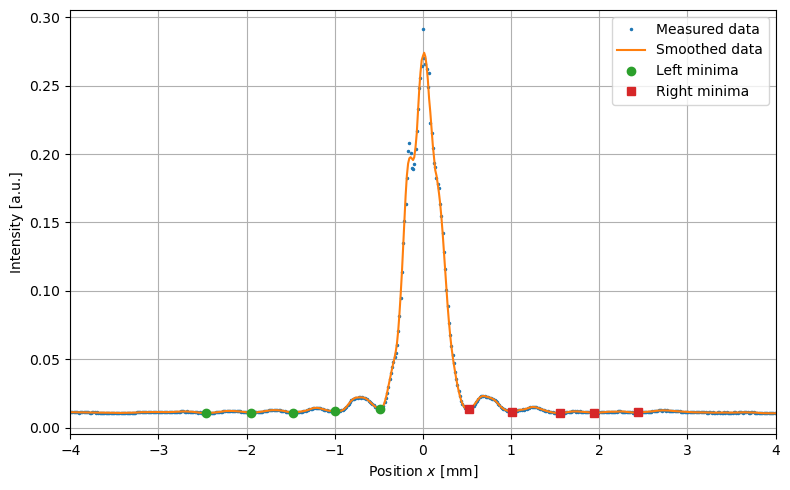

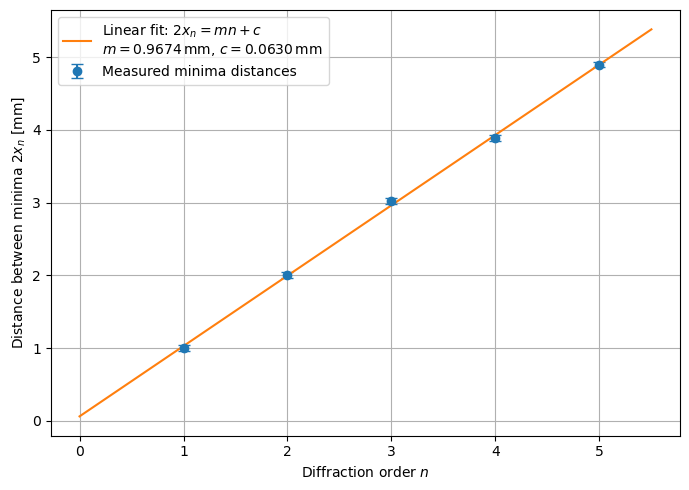

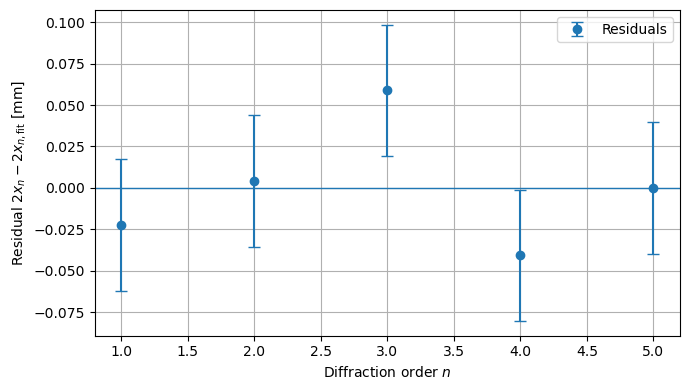

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.signal import savgol_filter
from scipy.optimize import curve_fit

# ============================================================
# User inputs
# ============================================================

csv_path = Path("task 1a, b.csv")   # change path if needed

lambda_laser = 636e-9               # m
u_lambda = 0.0                      # m, not specified; set to 1e-9 if you want to include wavelength uncertainty

f = 300.8e-3                        # m
u_f = 10e-3                         # m

pixel_width = 14e-6                 # m, new CCD camera
u_pixel_min = 2                     # pixels, uncertainty of each minimum position

b_manufacturer = 0.4e-3             # m

# Orders to analyze.
# For a 0.4 mm slit with f = 300.8 mm, first minima are about 34 pixels apart.
# If a higher-order minimum looks unreliable, remove it from this list.
orders = np.array([1, 2, 3, 4, 5])

# Search settings for automatic minima detection
search_half_width_pixels = 10       # search window around predicted minimum
savgol_window = 11                  # must be odd
savgol_polyorder = 3

# Output folder for plots
output_dir = Path("task1a_outputs")
output_dir.mkdir(exist_ok=True)

# ============================================================
# Load data
# ============================================================

data = np.loadtxt(csv_path, delimiter=",")
pixel = data[:, 0]
intensity = data[:, 1]

# Smooth intensity only for locating minima.
# Original intensity is kept for plotting.
intensity_smooth = savgol_filter(intensity, savgol_window, savgol_polyorder)

# Locate central maximum
p0 = pixel[np.argmax(intensity)]
I0 = np.max(intensity)

print(f"Central maximum pixel p0 = {p0:.0f}")
print(f"Maximum intensity = {I0:.6g} a.u.")

# ============================================================
# Detect minima around expected positions
# ============================================================

# Expected minimum spacing in metres and pixels using manufacturer slit width
x1_expected = f * lambda_laser / b_manufacturer
p_spacing_expected = x1_expected / pixel_width

print(f"Expected first minimum position = {x1_expected*1e3:.4f} mm")
print(f"Expected first minimum spacing = {p_spacing_expected:.2f} pixels")

left_min_pixels = []
right_min_pixels = []

for n in orders:
    p_left_expected = p0 - n * p_spacing_expected
    p_right_expected = p0 + n * p_spacing_expected

    left_mask = (
        (pixel >= p_left_expected - search_half_width_pixels)
        & (pixel <= p_left_expected + search_half_width_pixels)
    )
    right_mask = (
        (pixel >= p_right_expected - search_half_width_pixels)
        & (pixel <= p_right_expected + search_half_width_pixels)
    )

    if np.sum(left_mask) == 0 or np.sum(right_mask) == 0:
        raise ValueError(f"No data points found for order n={n}. Increase search_half_width_pixels.")

    left_indices = np.where(left_mask)[0]
    right_indices = np.where(right_mask)[0]

    left_idx = left_indices[np.argmin(intensity_smooth[left_indices])]
    right_idx = right_indices[np.argmin(intensity_smooth[right_indices])]

    left_min_pixels.append(pixel[left_idx])
    right_min_pixels.append(pixel[right_idx])

left_min_pixels = np.array(left_min_pixels)
right_min_pixels = np.array(right_min_pixels)

# Convert to positions relative to central maximum
x_left = (left_min_pixels - p0) * pixel_width
x_right = (right_min_pixels - p0) * pixel_width

# Distance between corresponding minima
two_x_n = x_right - x_left

# Uncertainty in distance between two minima:
# u(2x_n) = sqrt(u_left^2 + u_right^2)
u_x_single = u_pixel_min * pixel_width
u_two_x_n = np.sqrt(2) * u_x_single * np.ones_like(two_x_n)

# ============================================================
# Linear fit: 2 x_n = m n + c
# ============================================================

def linear_model(n, m, c):
    return m * n + c

popt, pcov = curve_fit(
    linear_model,
    orders,
    two_x_n,
    sigma=u_two_x_n,
    absolute_sigma=True
)

m_fit, c_fit = popt
u_m_fit, u_c_fit = np.sqrt(np.diag(pcov))

two_x_fit = linear_model(orders, m_fit, c_fit)
residuals = two_x_n - two_x_fit

SSE = np.sum(residuals**2)
MSE = SSE / len(orders)
RMSE = np.sqrt(MSE)

SS_tot = np.sum((two_x_n - np.mean(two_x_n))**2)
R2 = 1 - SSE / SS_tot

# Slit width from slope
b_exp = 2 * f * lambda_laser / m_fit

# Uncertainty propagation:
# b = 2 f lambda / m
u_b_exp = b_exp * np.sqrt(
    (u_f / f)**2
    + (u_lambda / lambda_laser)**2
    + (u_m_fit / m_fit)**2
)

relative_deviation = abs(b_exp - b_manufacturer) / b_manufacturer * 100

# ============================================================
# Results table
# ============================================================

results_table = pd.DataFrame({
    "order n": orders,
    "left minimum pixel": left_min_pixels,
    "right minimum pixel": right_min_pixels,
    "x_left [mm]": x_left * 1e3,
    "x_right [mm]": x_right * 1e3,
    "2x_n [mm]": two_x_n * 1e3,
    "u(2x_n) [mm]": u_two_x_n * 1e3
})

display(results_table)

print("\nLinear fit model:")
print("2 x_n = m n + c")

print("\nFit results:")
print(f"m = {m_fit*1e3:.6f} ± {u_m_fit*1e3:.6f} mm")
print(f"c = {c_fit*1e3:.6f} ± {u_c_fit*1e3:.6f} mm")

print("\nGoodness of fit:")
print(f"SSE  = {SSE:.6e} m^2")
print(f"MSE  = {MSE:.6e} m^2")
print(f"RMSE = {RMSE*1e3:.6f} mm")
print(f"R^2  = {R2:.6f}")

print("\nSingle-slit width:")
print(f"b_exp = {b_exp*1e3:.6f} ± {u_b_exp*1e3:.6f} mm")
print(f"b_manufacturer = {b_manufacturer*1e3:.6f} mm")
print(f"relative deviation = {relative_deviation:.3f} %")

# ============================================================
# Plot 1: Fraunhofer profile with detected minima
# ============================================================

x_mm = (pixel - p0) * pixel_width * 1e3

plt.figure(figsize=(8, 5))
plt.plot(x_mm, intensity, marker=".", linestyle="None", markersize=3, label="Measured data")
plt.plot(x_mm, intensity_smooth, linestyle="-", linewidth=1.5, label="Smoothed data")

plt.plot(x_left * 1e3, intensity[np.searchsorted(pixel, left_min_pixels)],
         marker="o", linestyle="None", markersize=6, label="Left minima")

plt.plot(x_right * 1e3, intensity[np.searchsorted(pixel, right_min_pixels)],
         marker="s", linestyle="None", markersize=6, label="Right minima")

plt.xlabel(r"Position $x$ [mm]")
plt.ylabel(r"Intensity [a.u.]")
plt.xlim(-4, 4)
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(output_dir / "task1a_single_slit_profile_minima.png", dpi=300)
plt.show()

# ============================================================
# Plot 2: Linear fit of 2x_n versus order n
# ============================================================

n_dense = np.linspace(0, orders.max() + 0.5, 300)
fit_dense = linear_model(n_dense, m_fit, c_fit)

plt.figure(figsize=(7, 5))
plt.errorbar(
    orders,
    two_x_n * 1e3,
    yerr=u_two_x_n * 1e3,
    fmt="o",
    capsize=4,
    label="Measured minima distances"
)
plt.plot(
    n_dense,
    fit_dense * 1e3,
    linestyle="-",
    label=(
        r"Linear fit: $2x_n = mn+c$" "\n"
        rf"$m = {m_fit*1e3:.4f}\,\mathrm{{mm}}$, "
        rf"$c = {c_fit*1e3:.4f}\,\mathrm{{mm}}$"
    )
)

plt.xlabel(r"Diffraction order $n$")
plt.ylabel(r"Distance between minima $2x_n$ [mm]")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(output_dir / "task1a_linear_fit_minima.png", dpi=300)
plt.show()

# ============================================================
# Plot 3: Residuals of linear fit
# ============================================================

plt.figure(figsize=(7, 4))
plt.axhline(0, linestyle="-", linewidth=1)
plt.errorbar(
    orders,
    residuals * 1e3,
    yerr=u_two_x_n * 1e3,
    fmt="o",
    capsize=4,
    label="Residuals"
)

plt.xlabel(r"Diffraction order $n$")
plt.ylabel(r"Residual $2x_n - 2x_{n,\mathrm{fit}}$ [mm]")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(output_dir / "task1a_linear_fit_residuals.png", dpi=300)
plt.show()

Number of data points = 2048
Central maximum pixel p0 = 1127
Estimated background = 0.00976997 a.u.
kx spacing dkx = 459.804 rad/m


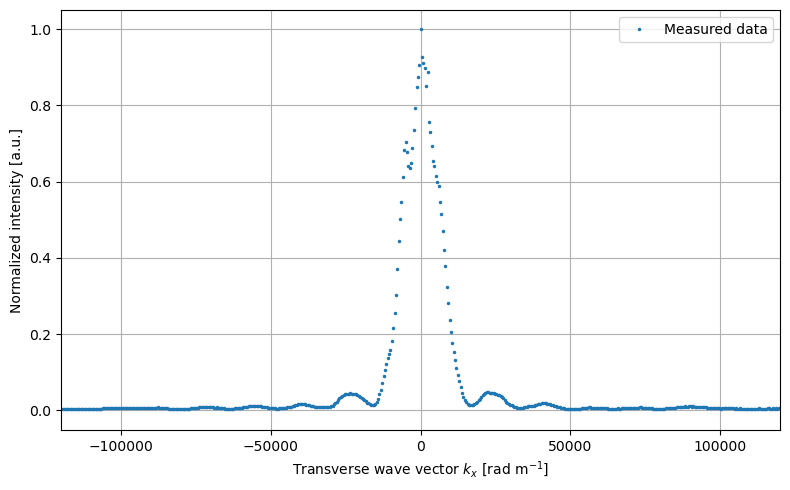


FFT-axis information:
x' spacing = 0.006672 mm
FFT resolution uncertainty = 0.003336 mm

Task 1b result from FFT:
b_FFT = 0.473735 ± 0.016099 mm

Comparison:
b_manufacturer = 0.400000 mm
relative deviation from manufacturer = 18.434 %
b_Task 1a = 0.395511 ± 0.014110 mm
relative difference from Task 1a = 19.778 %
normalized difference from Task 1a = 3.654


,Quantity,Value,Unit
0,Background intensity,0.009770,a.u.
1,kx spacing,459.804224,rad/m
2,FFT coordinate spacing,0.000007,m
3,b from FFT,0.000474,m
4,u(b) from FFT,0.000016,m
5,b from Task 1a,0.000396,m
6,u(b) from Task 1a,0.000014,m
7,manufacturer b,0.000400,m
8,relative deviation from manufacturer,18.433705,%
9,relative difference from Task 1a,19.777913,%


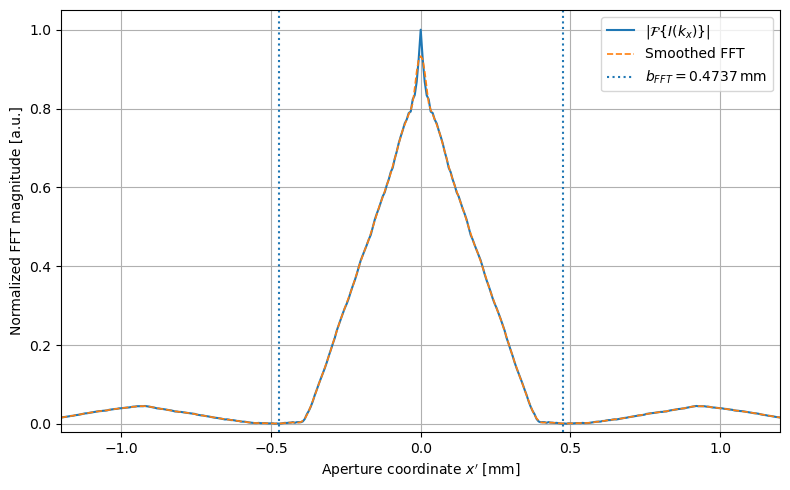

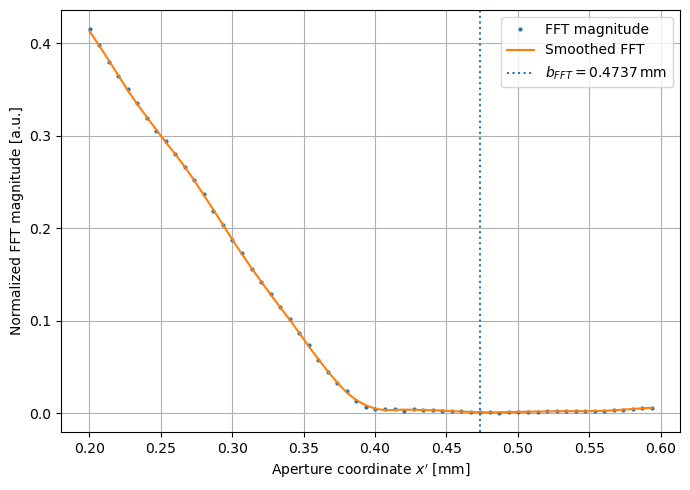

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.signal import savgol_filter
from scipy.optimize import curve_fit

# ============================================================
# User inputs
# ============================================================

csv_path = Path("task 1a, b.csv")   # change if needed

lambda_laser = 636e-9               # m
u_lambda = 0.0                      # m, not specified

f = 300.8e-3                        # m
u_f = 10e-3                         # m

pixel_width = 14e-6                 # m, new CCD camera
u_pixel_width = 0.0                 # m, not specified

b_manufacturer = 0.400e-3           # m

# Result from Task 1a for comparison
b_task1a = 0.395511e-3              # m
u_b_task1a = 0.014110e-3            # m

# FFT search settings
expected_b = b_manufacturer
search_window = 0.08e-3             # search +/- this range around expected b

# Optional smoothing for locating FFT minimum
savgol_window_fft = 9               # must be odd
savgol_polyorder_fft = 3

# Output folder
output_dir = Path("task1b_outputs")
output_dir.mkdir(exist_ok=True)

# ============================================================
# Load data
# ============================================================

data = np.loadtxt(csv_path, delimiter=",")
pixel = data[:, 0]
intensity = data[:, 1]

N = len(pixel)

# Central maximum
p0 = pixel[np.argmax(intensity)]

# Camera position axis
x = (pixel - p0) * pixel_width      # m

# For FFT, use small-angle kx relation.
# This gives an evenly spaced kx-axis because x is evenly spaced.
kx = (2 * np.pi / lambda_laser) * (x / f)   # rad/m

dkx = np.mean(np.diff(kx))

# Background subtraction
# Background estimated from both far edges of the CCD profile.
edge_points = 200
I_bg = np.median(np.r_[intensity[:edge_points], intensity[-edge_points:]])
I_corr = intensity - I_bg

# Optional: remove tiny negative values after background subtraction
# Do not clip for FFT unless necessary; leaving as-is preserves linearity.
I_norm = I_corr / np.max(I_corr)

print(f"Number of data points = {N}")
print(f"Central maximum pixel p0 = {p0:.0f}")
print(f"Estimated background = {I_bg:.6g} a.u.")
print(f"kx spacing dkx = {dkx:.6g} rad/m")

# ============================================================
# Plot 1: Measured Fraunhofer profile as a function of kx
# Required by checklist
# ============================================================

plt.figure(figsize=(8, 5))
plt.plot(kx, I_norm, marker=".", linestyle="None", markersize=3, label="Measured data")

plt.xlabel(r"Transverse wave vector $k_x$ [rad m$^{-1}$]")
plt.ylabel(r"Normalized intensity [a.u.]")
plt.xlim(-1.2e5, 1.2e5)
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(output_dir / "task1b_single_slit_intensity_kx.png", dpi=300)
plt.show()

# ============================================================
# FFT of I(kx)
# ============================================================

# The numpy FFT uses exp(-2 pi i n m/N).
# For a Fourier transform with exp(-i kx x'), the conjugate coordinate is:
# x' = 2*pi*fftfreq(N, d=dkx)
x_aperture = 2 * np.pi * np.fft.fftshift(np.fft.fftfreq(N, d=dkx))  # m

# Approximate continuous FT using factor dkx
fft_I = np.fft.fftshift(np.fft.fft(np.fft.ifftshift(I_norm))) * dkx
fft_mag = np.abs(fft_I)

# Normalize FFT magnitude
fft_mag_norm = fft_mag / np.max(fft_mag)

# Smooth FFT only for locating the first minimum
fft_mag_smooth = savgol_filter(fft_mag_norm, savgol_window_fft, savgol_polyorder_fft)

# ============================================================
# Determine slit width from FFT
# ============================================================

# For a single slit, the inverse FT/FFT of the intensity profile gives
# the autocorrelation of the slit transmission function.
# The central triangular autocorrelation reaches its first zero at |x'| = b.
# Therefore b is determined from the first minimum/zero near expected_b.

positive_mask = x_aperture > 0
x_pos = x_aperture[positive_mask]
fft_pos = fft_mag_norm[positive_mask]
fft_pos_smooth = fft_mag_smooth[positive_mask]

search_mask = (
    (x_pos >= expected_b - search_window)
    & (x_pos <= expected_b + search_window)
)

if np.sum(search_mask) == 0:
    raise ValueError("No FFT points found in the selected search window. Increase search_window.")

search_indices = np.where(search_mask)[0]
min_index_local = search_indices[np.argmin(fft_pos_smooth[search_indices])]

b_fft = x_pos[min_index_local]

# FFT-axis resolution
dx_aperture = np.mean(np.diff(x_aperture))
u_b_resolution = abs(dx_aperture) / 2

# Propagate scale uncertainty.
# Since x_aperture scale is proportional to lambda*f/pixel_width,
# include f and lambda uncertainties if specified.
u_b_fft = b_fft * np.sqrt(
    (u_f / f)**2
    + (u_lambda / lambda_laser)**2
    + (u_pixel_width / pixel_width)**2
    + (u_b_resolution / b_fft)**2
)

relative_deviation_manufacturer = abs(b_fft - b_manufacturer) / b_manufacturer * 100
relative_difference_task1a = abs(b_fft - b_task1a) / b_task1a * 100

combined_uncertainty_task1a = np.sqrt(u_b_fft**2 + u_b_task1a**2)
normalized_difference_task1a = abs(b_fft - b_task1a) / combined_uncertainty_task1a

print("\nFFT-axis information:")
print(f"x' spacing = {dx_aperture*1e3:.6f} mm")
print(f"FFT resolution uncertainty = {u_b_resolution*1e3:.6f} mm")

print("\nTask 1b result from FFT:")
print(f"b_FFT = {b_fft*1e3:.6f} ± {u_b_fft*1e3:.6f} mm")

print("\nComparison:")
print(f"b_manufacturer = {b_manufacturer*1e3:.6f} mm")
print(f"relative deviation from manufacturer = {relative_deviation_manufacturer:.3f} %")

print(f"b_Task 1a = {b_task1a*1e3:.6f} ± {u_b_task1a*1e3:.6f} mm")
print(f"relative difference from Task 1a = {relative_difference_task1a:.3f} %")
print(f"normalized difference from Task 1a = {normalized_difference_task1a:.3f}")

# ============================================================
# Results table
# ============================================================

results_table = pd.DataFrame({
    "Quantity": [
        "Background intensity",
        "kx spacing",
        "FFT coordinate spacing",
        "b from FFT",
        "u(b) from FFT",
        "b from Task 1a",
        "u(b) from Task 1a",
        "manufacturer b",
        "relative deviation from manufacturer",
        "relative difference from Task 1a",
        "normalized difference from Task 1a"
    ],
    "Value": [
        I_bg,
        dkx,
        dx_aperture,
        b_fft,
        u_b_fft,
        b_task1a,
        u_b_task1a,
        b_manufacturer,
        relative_deviation_manufacturer,
        relative_difference_task1a,
        normalized_difference_task1a
    ],
    "Unit": [
        "a.u.",
        "rad/m",
        "m",
        "m",
        "m",
        "m",
        "m",
        "m",
        "%",
        "%",
        "standard uncertainties"
    ]
})

display(results_table)

# ============================================================
# Plot 2: FFT magnitude as a function of aperture coordinate
# Required by checklist: FFT result with unit
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    x_aperture * 1e3,
    fft_mag_norm,
    linestyle="-",
    linewidth=1.5,
    label=r"$|\mathcal{F}\{I(k_x)\}|$"
)

plt.plot(
    x_aperture * 1e3,
    fft_mag_smooth,
    linestyle="--",
    linewidth=1.2,
    label="Smoothed FFT"
)

plt.axvline(b_fft * 1e3, linestyle=":", linewidth=1.5,
            label=rf"$b_{{FFT}}={b_fft*1e3:.4f}\,\mathrm{{mm}}$")
plt.axvline(-b_fft * 1e3, linestyle=":", linewidth=1.5)

plt.xlabel(r"Aperture coordinate $x'$ [mm]")
plt.ylabel(r"Normalized FFT magnitude [a.u.]")
plt.xlim(-1.2, 1.2)
plt.ylim(-0.02, 1.05)
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(output_dir / "task1b_fft_single_slit.png", dpi=300)
plt.show()

# ============================================================
# Plot 3: Zoomed FFT near positive first zero
# ============================================================

plt.figure(figsize=(7, 5))

zoom_mask = (
    (x_aperture >= 0.20e-3)
    & (x_aperture <= 0.60e-3)
)

plt.plot(
    x_aperture[zoom_mask] * 1e3,
    fft_mag_norm[zoom_mask],
    marker=".",
    linestyle="None",
    markersize=4,
    label="FFT magnitude"
)

plt.plot(
    x_aperture[zoom_mask] * 1e3,
    fft_mag_smooth[zoom_mask],
    linestyle="-",
    linewidth=1.5,
    label="Smoothed FFT"
)

plt.axvline(b_fft * 1e3, linestyle=":", linewidth=1.5,
            label=rf"$b_{{FFT}}={b_fft*1e3:.4f}\,\mathrm{{mm}}$")

plt.xlabel(r"Aperture coordinate $x'$ [mm]")
plt.ylabel(r"Normalized FFT magnitude [a.u.]")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(output_dir / "task1b_fft_single_slit_zero_zoom.png", dpi=300)
plt.show()

,Distance label,z [cm],u(z) [cm],central pixel p0,background [a.u.],noise estimate u(I) [norm. a.u.],Fresnel number N_b,u(N_b),A,u(A),C,u(C),x0 [mm],u(x0) [mm],RMSE [norm. a.u.],R^2
0,27 cm,27.0,0.5,1021.0,0.006629,0.000759,0.227738,0.016788,0.994884,0.000722,0.001525,0.000073,0.022031,0.000161,0.003264,0.998925
1,31 cm,31.0,0.5,1029.0,0.006018,0.001094,0.198353,0.014510,0.974555,0.000690,0.001220,0.000075,-0.009972,0.000179,0.003332,0.998975
2,35 cm,35.0,0.5,1035.0,0.007581,0.001151,0.175684,0.012784,0.975067,0.000521,0.001783,0.000060,-0.009132,0.000151,0.002665,0.999417


Input slit width from Task 1a:
b = 0.395511 ± 0.014110 mm

Distance uncertainty used:
u(z) = 0.500 cm

Pixel and centering uncertainty:
pixel width = 14.000 µm
u(center) = 2 pixels = 28.000 µm


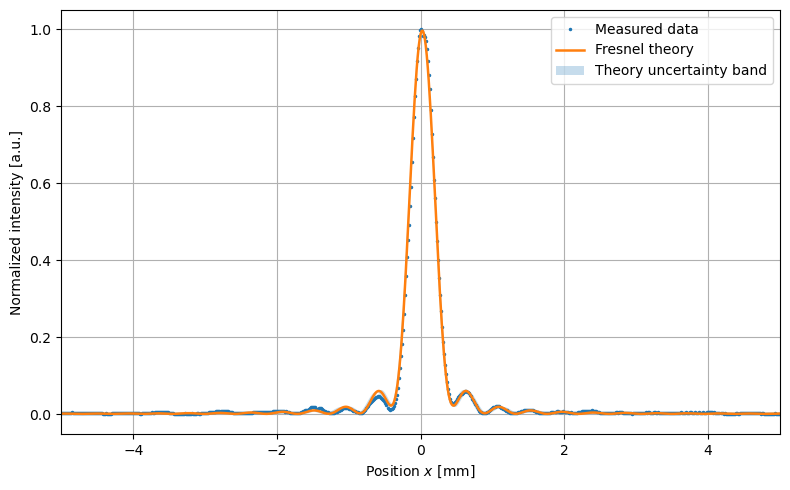

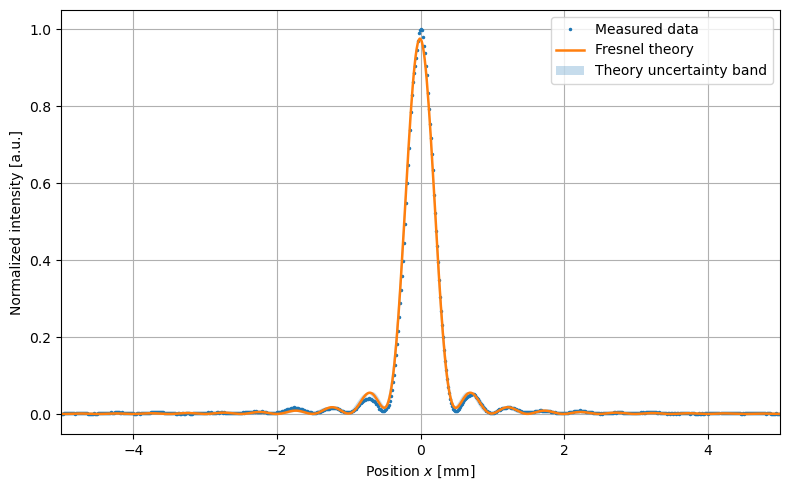

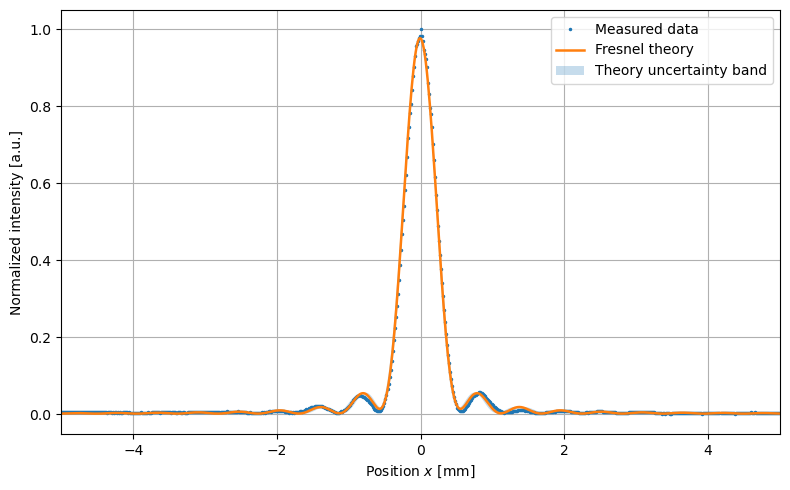

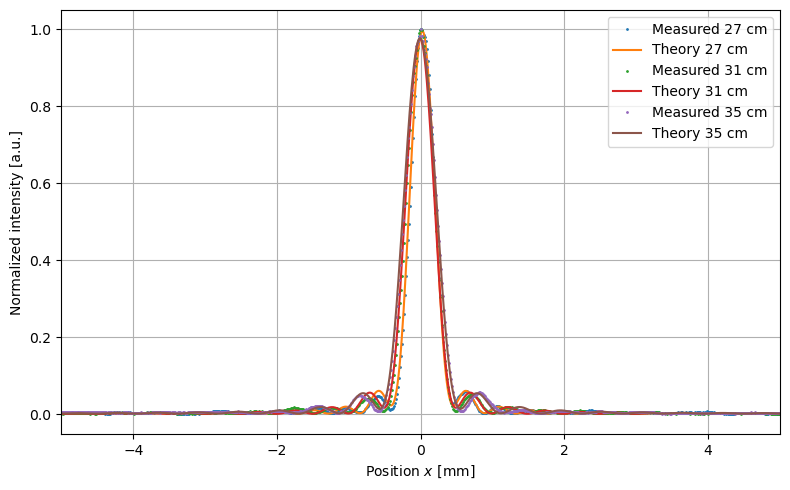

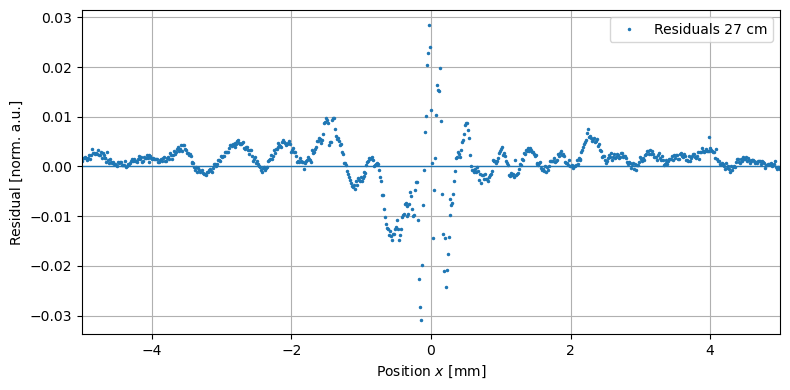

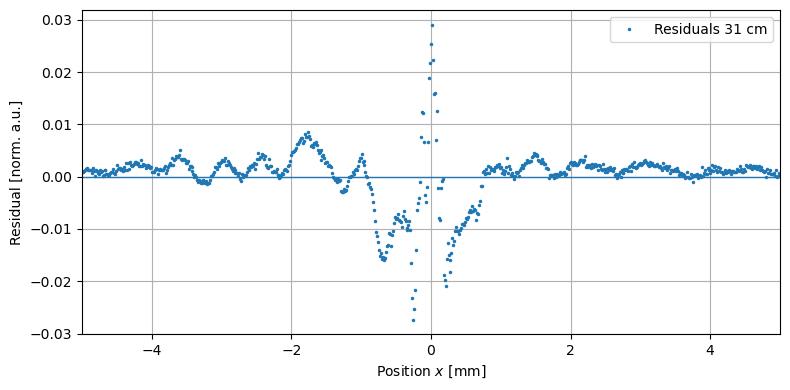

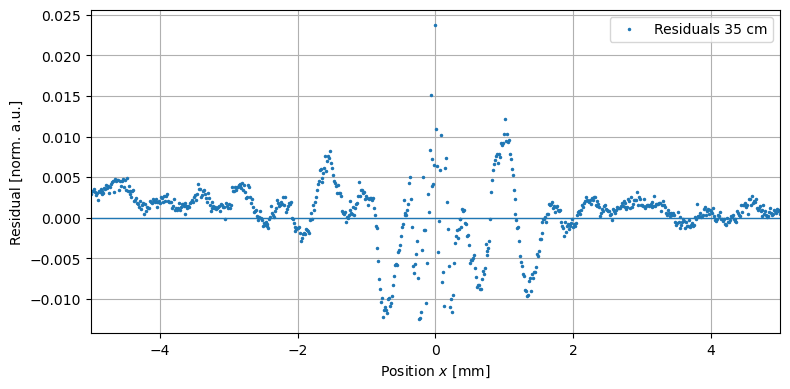

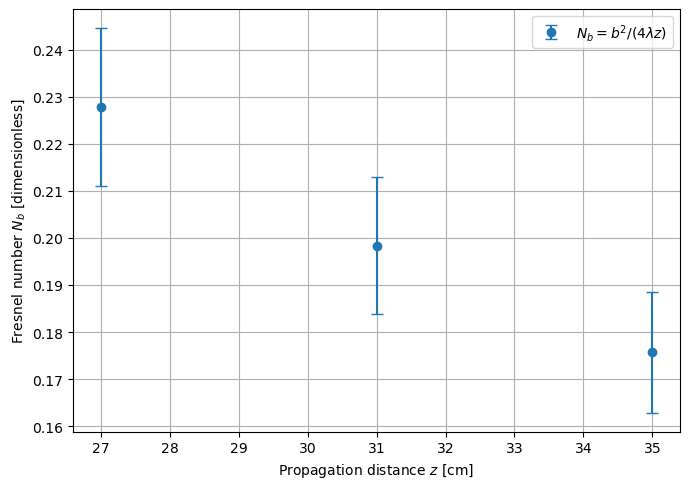


Saved files:
task1c_outputs\task1c_all_fresnel_profiles.png
task1c_outputs\task1c_fresnel_number_vs_distance.png
task1c_outputs\task1c_fresnel_profile_27_cm.png
task1c_outputs\task1c_fresnel_profile_31_cm.png
task1c_outputs\task1c_fresnel_profile_35_cm.png
task1c_outputs\task1c_residuals_27_cm.png
task1c_outputs\task1c_residuals_31_cm.png
task1c_outputs\task1c_residuals_35_cm.png
task1c_outputs\task1c_summary_table.csv


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.special import fresnel
from scipy.optimize import curve_fit

# ============================================================
# User inputs
# ============================================================

files = {
    "27 cm": {
        "path": Path("task 1c 27cm.csv"),
        "z": 27e-2
    },
    "31 cm": {
        "path": Path("task 1c 31cm.csv"),
        "z": 31e-2
    },
    "35 cm": {
        "path": Path("task 1c 35cm.csv"),
        "z": 35e-2
    }
}

lambda_laser = 636e-9          # m
u_lambda = 0.0                 # m, not specified; set to 1e-9 if desired

pixel_width = 14e-6            # m, new CCD camera
u_pixel_width = 0.0            # m, not specified

# Use Task 1a slit width, as recommended by the manual
b = 0.395511e-3                # m
u_b = 0.014110e-3              # m

# Distance uncertainty.
# Change this if your lab notes have a more precise value.
u_z = 0.5e-2                   # m = 0.5 cm

# Uncertainty in locating the profile center
u_center_pixel = 2             # pixels

# Background estimation
edge_points = 200

# Plot range
x_plot_limit_mm = 5

# Output folder
output_dir = Path("task1c_outputs")
output_dir.mkdir(exist_ok=True)

# ============================================================
# Fresnel theory functions
# ============================================================

def complex_fresnel_F(u):
    """
    scipy.special.fresnel returns S(u), C(u).
    The complex Fresnel integral used here is F(u) = C(u) + i S(u).
    """
    S, C = fresnel(u)
    return C + 1j * S


def single_slit_fresnel_intensity(x, z, b, wavelength):
    """
    Single-slit Fresnel diffraction intensity.

    I(x,z) ∝ | F((b+2x)/sqrt(2 lambda z))
              + F((b-2x)/sqrt(2 lambda z)) |^2
    """
    denom = np.sqrt(2 * wavelength * z)

    u1 = (b + 2 * x) / denom
    u2 = (b - 2 * x) / denom

    field = complex_fresnel_F(u1) + complex_fresnel_F(u2)
    intensity = np.abs(field)**2

    return intensity


def normalized_theory(x, z, b, wavelength):
    """
    Background-free normalized Fresnel theory curve.
    """
    I = single_slit_fresnel_intensity(x, z, b, wavelength)
    return I / np.max(I)


def fit_model(x, A, C, x0, z, b, wavelength):
    """
    Fit model for measured normalized intensity.

    A  = amplitude scale
    C  = vertical offset
    x0 = horizontal offset
    """
    return A * normalized_theory(x - x0, z, b, wavelength) + C


def rmse(y, yfit):
    return np.sqrt(np.mean((y - yfit)**2))


def r_squared(y, yfit):
    ss_res = np.sum((y - yfit)**2)
    ss_tot = np.sum((y - np.mean(y))**2)
    return 1 - ss_res / ss_tot


# ============================================================
# Analysis loop
# ============================================================

summary_rows = []
processed = {}

for label, info in files.items():

    path = info["path"]
    z = info["z"]

    # --------------------------------------------------------
    # Load data
    # --------------------------------------------------------

    data = np.loadtxt(path, delimiter=",")
    pixel = data[:, 0]
    intensity = data[:, 1]

    N = len(pixel)

    # Central maximum
    p0 = pixel[np.argmax(intensity)]

    # Position axis, centered at the maximum
    x = (pixel - p0) * pixel_width

    # Background correction and normalization
    I_bg = np.median(np.r_[intensity[:edge_points], intensity[-edge_points:]])
    I_corr = intensity - I_bg
    I_norm = I_corr / np.max(I_corr)

    # Estimate intensity noise from background regions after normalization
    bg_norm = np.r_[I_norm[:edge_points], I_norm[-edge_points:]]
    u_I = np.std(bg_norm)

    # Fresnel number and uncertainty
    N_b = b**2 / (4 * lambda_laser * z)

    u_N_b = N_b * np.sqrt(
        (2 * u_b / b)**2
        + (u_lambda / lambda_laser)**2
        + (u_z / z)**2
    )

    # --------------------------------------------------------
    # Fit scale, vertical offset, and horizontal offset
    # b and z are kept fixed to measured values.
    # --------------------------------------------------------

    def model_for_curve_fit(xdata, A, C, x0):
        return fit_model(xdata, A, C, x0, z, b, lambda_laser)

    initial_guess = [1.0, 0.0, 0.0]

    # Allow only small horizontal shifts
    x0_bound = 10 * pixel_width

    bounds = (
        [0.0, -0.5, -x0_bound],
        [2.0,  0.5,  x0_bound]
    )

    popt, pcov = curve_fit(
        model_for_curve_fit,
        x,
        I_norm,
        p0=initial_guess,
        bounds=bounds,
        maxfev=20000
    )

    A_fit, C_fit, x0_fit = popt
    u_A_fit, u_C_fit, u_x0_fit = np.sqrt(np.diag(pcov))

    I_fit = model_for_curve_fit(x, A_fit, C_fit, x0_fit)

    residuals = I_norm - I_fit

    RMSE = rmse(I_norm, I_fit)
    R2 = r_squared(I_norm, I_fit)

    # --------------------------------------------------------
    # Theory uncertainty band from b and z uncertainties
    # --------------------------------------------------------

    theory_curves = []

    for b_i in [b - u_b, b, b + u_b]:
        for z_i in [z - u_z, z, z + u_z]:
            if b_i > 0 and z_i > 0:
                theory_curves.append(
                    fit_model(x, A_fit, C_fit, x0_fit, z_i, b_i, lambda_laser)
                )

    theory_curves = np.array(theory_curves)
    theory_lower = np.min(theory_curves, axis=0)
    theory_upper = np.max(theory_curves, axis=0)

    # --------------------------------------------------------
    # Store results
    # --------------------------------------------------------

    processed[label] = {
        "pixel": pixel,
        "intensity": intensity,
        "x": x,
        "I_norm": I_norm,
        "I_fit": I_fit,
        "residuals": residuals,
        "theory_lower": theory_lower,
        "theory_upper": theory_upper,
        "p0": p0,
        "z": z,
        "I_bg": I_bg,
        "u_I": u_I,
        "N_b": N_b,
        "u_N_b": u_N_b,
        "A_fit": A_fit,
        "u_A_fit": u_A_fit,
        "C_fit": C_fit,
        "u_C_fit": u_C_fit,
        "x0_fit": x0_fit,
        "u_x0_fit": u_x0_fit,
        "RMSE": RMSE,
        "R2": R2
    }

    summary_rows.append({
        "Distance label": label,
        "z [cm]": z * 100,
        "u(z) [cm]": u_z * 100,
        "central pixel p0": p0,
        "background [a.u.]": I_bg,
        "noise estimate u(I) [norm. a.u.]": u_I,
        "Fresnel number N_b": N_b,
        "u(N_b)": u_N_b,
        "A": A_fit,
        "u(A)": u_A_fit,
        "C": C_fit,
        "u(C)": u_C_fit,
        "x0 [mm]": x0_fit * 1e3,
        "u(x0) [mm]": u_x0_fit * 1e3,
        "RMSE [norm. a.u.]": RMSE,
        "R^2": R2
    })


summary_table = pd.DataFrame(summary_rows)
display(summary_table)

print("Input slit width from Task 1a:")
print(f"b = {b*1e3:.6f} ± {u_b*1e3:.6f} mm")

print("\nDistance uncertainty used:")
print(f"u(z) = {u_z*100:.3f} cm")

print("\nPixel and centering uncertainty:")
print(f"pixel width = {pixel_width*1e6:.3f} µm")
print(f"u(center) = {u_center_pixel} pixels = {u_center_pixel*pixel_width*1e6:.3f} µm")

# ============================================================
# Plot 1: Each Fresnel profile with corresponding theory curve
# ============================================================

for label, result in processed.items():

    x_mm = result["x"] * 1e3

    plt.figure(figsize=(8, 5))

    plt.plot(
        x_mm,
        result["I_norm"],
        marker=".",
        linestyle="None",
        markersize=3,
        label="Measured data"
    )

    plt.plot(
        x_mm,
        result["I_fit"],
        linestyle="-",
        linewidth=1.8,
        label="Fresnel theory"
    )

    plt.fill_between(
        x_mm,
        result["theory_lower"],
        result["theory_upper"],
        alpha=0.25,
        label=r"Theory uncertainty band"
    )

    plt.xlabel(r"Position $x$ [mm]")
    plt.ylabel(r"Normalized intensity [a.u.]")
    plt.xlim(-x_plot_limit_mm, x_plot_limit_mm)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    save_name = f"task1c_fresnel_profile_{label.replace(' ', '_')}.png"
    plt.savefig(output_dir / save_name, dpi=300)
    plt.show()

# ============================================================
# Plot 2: All three Fresnel profiles compared in one plot
# ============================================================

plt.figure(figsize=(8, 5))

for label, result in processed.items():

    x_mm = result["x"] * 1e3

    plt.plot(
        x_mm,
        result["I_norm"],
        marker=".",
        linestyle="None",
        markersize=2,
        label=f"Measured {label}"
    )

    plt.plot(
        x_mm,
        result["I_fit"],
        linestyle="-",
        linewidth=1.5,
        label=f"Theory {label}"
    )

plt.xlabel(r"Position $x$ [mm]")
plt.ylabel(r"Normalized intensity [a.u.]")
plt.xlim(-x_plot_limit_mm, x_plot_limit_mm)
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(output_dir / "task1c_all_fresnel_profiles.png", dpi=300)
plt.show()

# ============================================================
# Plot 3: Residuals for each distance
# ============================================================

for label, result in processed.items():

    x_mm = result["x"] * 1e3

    plt.figure(figsize=(8, 4))

    plt.axhline(0, linestyle="-", linewidth=1)

    plt.plot(
        x_mm,
        result["residuals"],
        marker=".",
        linestyle="None",
        markersize=3,
        label=f"Residuals {label}"
    )

    plt.xlabel(r"Position $x$ [mm]")
    plt.ylabel(r"Residual [norm. a.u.]")
    plt.xlim(-x_plot_limit_mm, x_plot_limit_mm)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    save_name = f"task1c_residuals_{label.replace(' ', '_')}.png"
    plt.savefig(output_dir / save_name, dpi=300)
    plt.show()

# ============================================================
# Plot 4: Fresnel number versus distance
# ============================================================

z_values_cm = np.array([processed[label]["z"] * 100 for label in processed])
N_values = np.array([processed[label]["N_b"] for label in processed])
u_N_values = np.array([processed[label]["u_N_b"] for label in processed])

plt.figure(figsize=(7, 5))

plt.errorbar(
    z_values_cm,
    N_values,
    yerr=u_N_values,
    fmt="o",
    capsize=4,
    label=r"$N_b=b^2/(4\lambda z)$"
)

plt.xlabel(r"Propagation distance $z$ [cm]")
plt.ylabel(r"Fresnel number $N_b$ [dimensionless]")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(output_dir / "task1c_fresnel_number_vs_distance.png", dpi=300)
plt.show()

# ============================================================
# Save summary table as CSV
# ============================================================

summary_table.to_csv(output_dir / "task1c_summary_table.csv", index=False)

print("\nSaved files:")
for file in sorted(output_dir.glob("*.png")):
    print(file)
print(output_dir / "task1c_summary_table.csv")

Central maximum pixel p0 = 1125
Maximum intensity = 0.295956 a.u.

Expected minima positions from manufacturer g:
n =  0, expected |x_n| = 0.1275 mm, expected pixel offset = 9.11
n =  1, expected |x_n| = 0.3826 mm, expected pixel offset = 27.33
n =  2, expected |x_n| = 0.6377 mm, expected pixel offset = 45.55
n =  3, expected |x_n| = 0.8928 mm, expected pixel offset = 63.77
n =  4, expected |x_n| = 1.1479 mm, expected pixel offset = 81.99
n =  5, expected |x_n| = 1.4029 mm, expected pixel offset = 100.21
n =  6, expected |x_n| = 1.6580 mm, expected pixel offset = 118.43
n =  7, expected |x_n| = 1.9131 mm, expected pixel offset = 136.65
n =  8, expected |x_n| = 2.1682 mm, expected pixel offset = 154.87


,order n,n + 1/2,left minimum pixel,right minimum pixel,x_left [mm],x_right [mm],2x_n [mm],u(2x_n) [mm]
0,0,0.5,1116.0,1135.0,-0.126,0.140,0.266,0.039598
1,1,1.5,1098.0,1154.0,-0.378,0.406,0.784,0.039598
2,2,2.5,1079.0,1173.0,-0.644,0.672,1.316,0.039598
3,3,3.5,1058.0,1193.0,-0.938,0.952,1.890,0.039598
4,4,4.5,1043.0,1204.0,-1.148,1.106,2.254,0.039598
5,5,5.5,1024.0,1225.0,-1.414,1.400,2.814,0.039598
6,6,6.5,1006.0,1244.0,-1.666,1.666,3.332,0.039598
7,7,7.5,988.0,1266.0,-1.918,1.974,3.892,0.039598
8,8,8.5,971.0,1275.0,-2.156,2.100,4.256,0.039598



Linear fit model:
2 x_n = m (n + 1/2) + c

Fit results:
m = 0.504000 ± 0.005112 mm
c = 0.043556 ± 0.026522 mm

Goodness of fit:
SSE  = 2.134222e-08 m^2
MSE  = 2.371358e-09 m^2
RMSE = 0.048697 mm
R^2  = 0.998602

Double-slit separation:
g_exp = 0.759162 ± 0.026387 mm
g_manufacturer = 0.750000 mm
relative deviation = 1.222 %

Note:
Task 2a determines the slit separation g from interference minima.
The slit width b is determined more reliably from the envelope or the full fit in Task 2b.


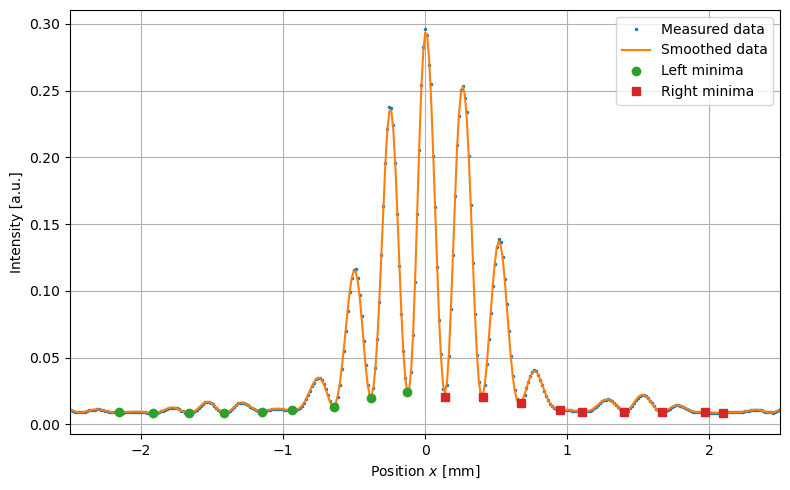

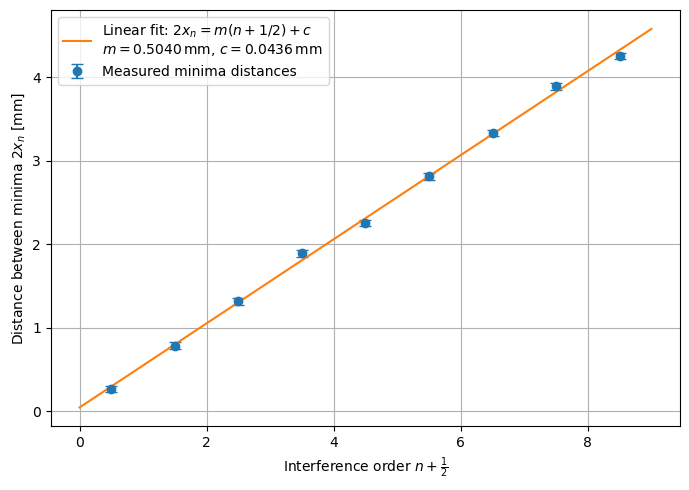

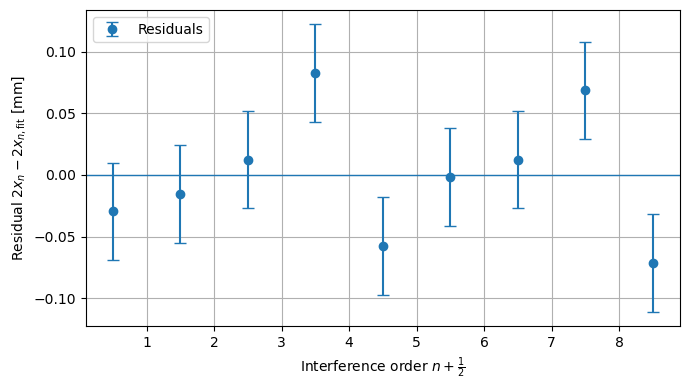


Saved files:
task2a_outputs\task2a_double_slit_profile_minima.png
task2a_outputs\task2a_linear_fit_minima.png
task2a_outputs\task2a_linear_fit_residuals.png
task2a_outputs\task2a_minima_table.csv


In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.signal import savgol_filter
from scipy.optimize import curve_fit

# ============================================================
# User inputs
# ============================================================

csv_path = Path("task 2a, b (2).csv")   # change path if needed

lambda_laser = 636e-9                   # m
u_lambda = 0.0                          # m, not specified

f = 300.8e-3                            # m
u_f = 10e-3                             # m

pixel_width = 14e-6                     # m, new CCD camera
u_pixel_min = 2                         # pixels, uncertainty of each minimum position

g_manufacturer = 0.75e-3                # m
b_manufacturer = 0.20e-3                # m

# Double-slit interference minima:
# g sin(alpha_n) = (n + 1/2) lambda
# x_n ≈ f lambda (n + 1/2) / g
#
# For g = 0.75 mm, first minima are at about 12.75 pixels from the center.
# Use orders n = 0,1,2,... for minima of the cos^2 interference term.
orders = np.array([0, 1, 2, 3, 4, 5, 6, 7, 8])

# Automatic minima search settings
search_half_width_pixels = 5
savgol_window = 9                       # must be odd
savgol_polyorder = 3

# Plot range
x_plot_limit_mm = 2.5

# Output folder
output_dir = Path("task2a_outputs")
output_dir.mkdir(exist_ok=True)

# ============================================================
# Load data
# ============================================================

data = np.loadtxt(csv_path, delimiter=",")
pixel = data[:, 0]
intensity = data[:, 1]

# Smooth intensity only for locating minima
intensity_smooth = savgol_filter(intensity, savgol_window, savgol_polyorder)

# Locate central maximum
p0 = pixel[np.argmax(intensity)]
I0 = np.max(intensity)

print(f"Central maximum pixel p0 = {p0:.0f}")
print(f"Maximum intensity = {I0:.6g} a.u.")

# ============================================================
# Detect double-slit interference minima
# ============================================================

# Expected minima positions from manufacturer g
x_min_expected = f * lambda_laser * (orders + 0.5) / g_manufacturer
p_spacing_expected = x_min_expected / pixel_width

print("\nExpected minima positions from manufacturer g:")
for n, pspace in zip(orders, p_spacing_expected):
    print(f"n = {n:2d}, expected |x_n| = {pspace*pixel_width*1e3:.4f} mm, "
          f"expected pixel offset = {pspace:.2f}")

left_min_pixels = []
right_min_pixels = []

for n, p_offset in zip(orders, p_spacing_expected):

    p_left_expected = p0 - p_offset
    p_right_expected = p0 + p_offset

    left_mask = (
        (pixel >= p_left_expected - search_half_width_pixels)
        & (pixel <= p_left_expected + search_half_width_pixels)
    )
    right_mask = (
        (pixel >= p_right_expected - search_half_width_pixels)
        & (pixel <= p_right_expected + search_half_width_pixels)
    )

    if np.sum(left_mask) == 0 or np.sum(right_mask) == 0:
        raise ValueError(
            f"No data points found for order n={n}. "
            "Increase search_half_width_pixels or reduce number of orders."
        )

    left_indices = np.where(left_mask)[0]
    right_indices = np.where(right_mask)[0]

    left_idx = left_indices[np.argmin(intensity_smooth[left_indices])]
    right_idx = right_indices[np.argmin(intensity_smooth[right_indices])]

    left_min_pixels.append(pixel[left_idx])
    right_min_pixels.append(pixel[right_idx])

left_min_pixels = np.array(left_min_pixels)
right_min_pixels = np.array(right_min_pixels)

# Convert to positions relative to central maximum
x_left = (left_min_pixels - p0) * pixel_width
x_right = (right_min_pixels - p0) * pixel_width

# Distance between corresponding minima
two_x_n = x_right - x_left

# x-axis variable for linear fit is n + 1/2
n_half = orders + 0.5

# Uncertainty in distance between two minima
u_x_single = u_pixel_min * pixel_width
u_two_x_n = np.sqrt(2) * u_x_single * np.ones_like(two_x_n)

# ============================================================
# Linear fit: 2 x_n = m (n + 1/2) + c
# ============================================================

def linear_model(q, m, c):
    return m * q + c

popt, pcov = curve_fit(
    linear_model,
    n_half,
    two_x_n,
    sigma=u_two_x_n,
    absolute_sigma=True
)

m_fit, c_fit = popt
u_m_fit, u_c_fit = np.sqrt(np.diag(pcov))

two_x_fit = linear_model(n_half, m_fit, c_fit)
residuals = two_x_n - two_x_fit

SSE = np.sum(residuals**2)
MSE = SSE / len(n_half)
RMSE = np.sqrt(MSE)

SS_tot = np.sum((two_x_n - np.mean(two_x_n))**2)
R2 = 1 - SSE / SS_tot

# Slit distance from slope
g_exp = 2 * f * lambda_laser / m_fit

u_g_exp = g_exp * np.sqrt(
    (u_f / f)**2
    + (u_lambda / lambda_laser)**2
    + (u_m_fit / m_fit)**2
)

relative_deviation = abs(g_exp - g_manufacturer) / g_manufacturer * 100

# ============================================================
# Results table
# ============================================================

results_table = pd.DataFrame({
    "order n": orders,
    "n + 1/2": n_half,
    "left minimum pixel": left_min_pixels,
    "right minimum pixel": right_min_pixels,
    "x_left [mm]": x_left * 1e3,
    "x_right [mm]": x_right * 1e3,
    "2x_n [mm]": two_x_n * 1e3,
    "u(2x_n) [mm]": u_two_x_n * 1e3
})

display(results_table)

print("\nLinear fit model:")
print("2 x_n = m (n + 1/2) + c")

print("\nFit results:")
print(f"m = {m_fit*1e3:.6f} ± {u_m_fit*1e3:.6f} mm")
print(f"c = {c_fit*1e3:.6f} ± {u_c_fit*1e3:.6f} mm")

print("\nGoodness of fit:")
print(f"SSE  = {SSE:.6e} m^2")
print(f"MSE  = {MSE:.6e} m^2")
print(f"RMSE = {RMSE*1e3:.6f} mm")
print(f"R^2  = {R2:.6f}")

print("\nDouble-slit separation:")
print(f"g_exp = {g_exp*1e3:.6f} ± {u_g_exp*1e3:.6f} mm")
print(f"g_manufacturer = {g_manufacturer*1e3:.6f} mm")
print(f"relative deviation = {relative_deviation:.3f} %")

print("\nNote:")
print("Task 2a determines the slit separation g from interference minima.")
print("The slit width b is determined more reliably from the envelope or the full fit in Task 2b.")

# ============================================================
# Plot 1: Double-slit Fraunhofer profile with detected minima
# ============================================================

x_mm = (pixel - p0) * pixel_width * 1e3

plt.figure(figsize=(8, 5))
plt.plot(
    x_mm,
    intensity,
    marker=".",
    linestyle="None",
    markersize=3,
    label="Measured data"
)
plt.plot(
    x_mm,
    intensity_smooth,
    linestyle="-",
    linewidth=1.5,
    label="Smoothed data"
)

plt.plot(
    x_left * 1e3,
    intensity[np.searchsorted(pixel, left_min_pixels)],
    marker="o",
    linestyle="None",
    markersize=6,
    label="Left minima"
)

plt.plot(
    x_right * 1e3,
    intensity[np.searchsorted(pixel, right_min_pixels)],
    marker="s",
    linestyle="None",
    markersize=6,
    label="Right minima"
)

plt.xlabel(r"Position $x$ [mm]")
plt.ylabel(r"Intensity [a.u.]")
plt.xlim(-x_plot_limit_mm, x_plot_limit_mm)
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(output_dir / "task2a_double_slit_profile_minima.png", dpi=300)
plt.show()

# ============================================================
# Plot 2: Linear fit of 2x_n versus n + 1/2
# ============================================================

q_dense = np.linspace(0, n_half.max() + 0.5, 300)
fit_dense = linear_model(q_dense, m_fit, c_fit)

plt.figure(figsize=(7, 5))
plt.errorbar(
    n_half,
    two_x_n * 1e3,
    yerr=u_two_x_n * 1e3,
    fmt="o",
    capsize=4,
    label="Measured minima distances"
)

plt.plot(
    q_dense,
    fit_dense * 1e3,
    linestyle="-",
    label=(
        r"Linear fit: $2x_n=m(n+1/2)+c$" "\n"
        rf"$m={m_fit*1e3:.4f}\,\mathrm{{mm}}$, "
        rf"$c={c_fit*1e3:.4f}\,\mathrm{{mm}}$"
    )
)

plt.xlabel(r"Interference order $n+\frac{1}{2}$")
plt.ylabel(r"Distance between minima $2x_n$ [mm]")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(output_dir / "task2a_linear_fit_minima.png", dpi=300)
plt.show()

# ============================================================
# Plot 3: Residuals
# ============================================================

plt.figure(figsize=(7, 4))
plt.axhline(0, linestyle="-", linewidth=1)

plt.errorbar(
    n_half,
    residuals * 1e3,
    yerr=u_two_x_n * 1e3,
    fmt="o",
    capsize=4,
    label="Residuals"
)

plt.xlabel(r"Interference order $n+\frac{1}{2}$")
plt.ylabel(r"Residual $2x_n-2x_{n,\mathrm{fit}}$ [mm]")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(output_dir / "task2a_linear_fit_residuals.png", dpi=300)
plt.show()

# ============================================================
# Save table
# ============================================================

results_table.to_csv(output_dir / "task2a_minima_table.csv", index=False)

print("\nSaved files:")
for file in sorted(output_dir.glob("*")):
    print(file)

Number of data points = 2048
Central maximum pixel p0 = 1125
Maximum intensity = 0.295956 a.u.
Estimated background = 0.007352 a.u.
Estimated normalized intensity noise = 0.000905


C:\Users\laiba\AppData\Local\Temp\ipykernel_16144\566300897.py:88: RuntimeWarning: invalid value encountered in divide
  return np.where(np.abs(u) < 1e-14, 1.0, np.sin(u) / u)


,Quantity,Value,Unit
0,A,1.006131e+00,norm. a.u.
1,b from fit,1.843127e-04,m
2,u(b) covariance only,9.300673e-07,m
3,u(b) scale only,6.127415e-06,m
4,u(b) total,6.197600e-06,m
5,g from fit,7.349037e-04,m
6,u(g) covariance only,7.743934e-07,m
7,u(g) scale only,2.443164e-05,m
8,u(g) total,2.444391e-05,m
9,C,9.591872e-03,norm. a.u.



Fit model:
I(kx) = A sinc^2[b(kx-kx0)/2] cos^2[g(kx-kx0)/2] + C

Fitted parameters:
A   = 1.006131 ± 0.004968
b   = 0.184313 ± 0.006198 mm
g   = 0.734904 ± 0.024444 mm
C   = 0.009592 ± 0.001065
kx0 = 289.569921 ± 9.470064 rad/m

Uncertainty components:
u(b) from covariance = 0.000930 mm
u(b) from scale      = 0.006127 mm
u(g) from covariance = 0.000774 mm
u(g) from scale      = 0.024432 mm

Goodness of fit:
SSE  = 1.086048e-01
MSE  = 3.042152e-04
RMSE = 0.017442
R^2  = 0.992906

Comparison:
b_manufacturer = 0.200000 mm
relative deviation b = 7.844 %
g_manufacturer = 0.750000 mm
relative deviation g = 2.013 %
g_Task 2a = 0.759162 ± 0.026387 mm
relative difference from Task 2a = 3.195 %
normalized difference from Task 2a = 0.674


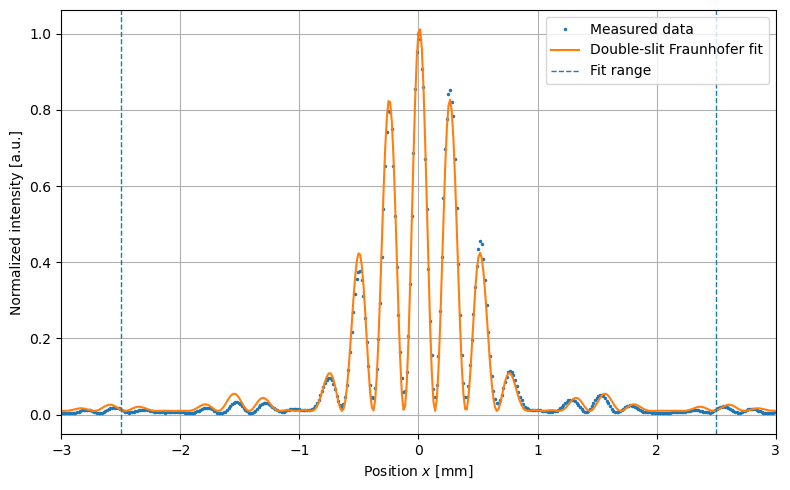

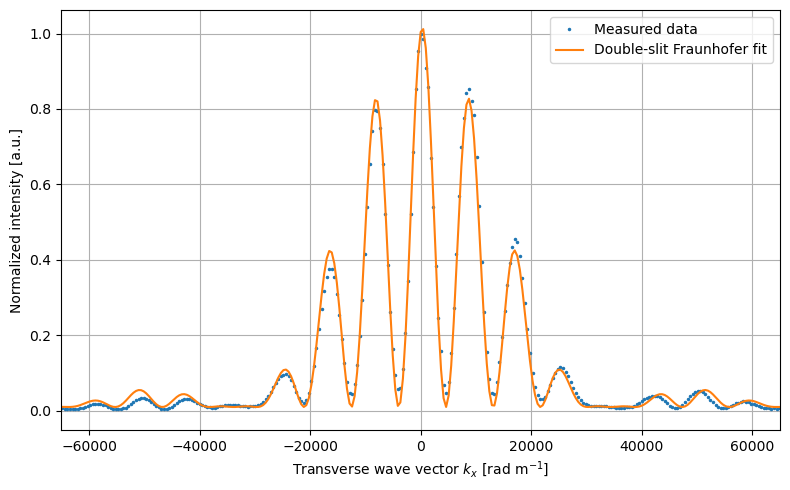

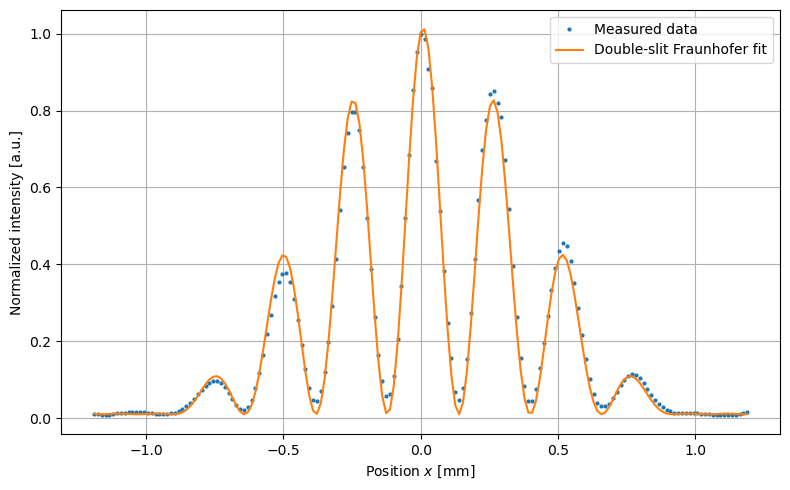

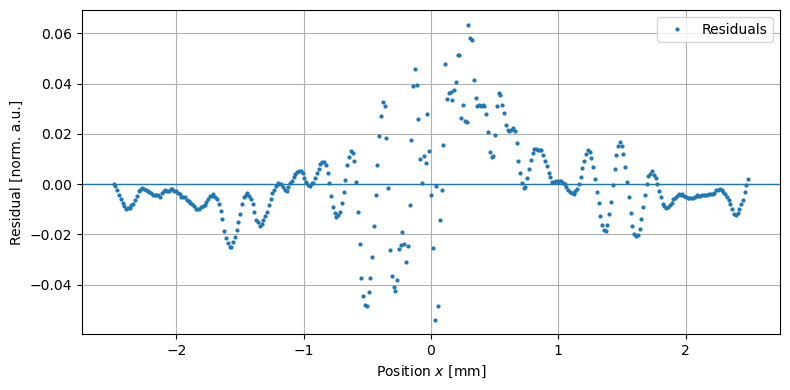

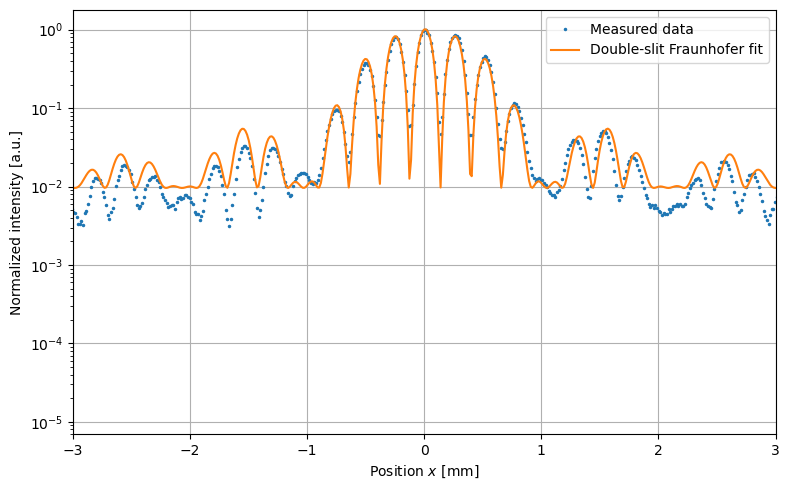


Saved files:
task2b_outputs\task2b_double_slit_fit_kx.png
task2b_outputs\task2b_double_slit_fit_position.png
task2b_outputs\task2b_double_slit_fit_residuals.png
task2b_outputs\task2b_double_slit_fit_semilog.png
task2b_outputs\task2b_double_slit_fit_zoom.png
task2b_outputs\task2b_fit_results.csv


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.optimize import curve_fit

# ============================================================
# User inputs
# ============================================================

csv_path = Path("task 2a, b (2).csv")   # change path if needed

lambda_laser = 636e-9                   # m
u_lambda = 0.0                          # m, not specified

f = 300.8e-3                            # m
u_f = 10e-3                             # m

pixel_width = 14e-6                     # m, new CCD camera
u_pixel_width = 0.0                     # m, not specified

b_manufacturer = 0.20e-3                # m
g_manufacturer = 0.75e-3                # m

# Task 2a result for comparison
g_task2a = 0.759162e-3                  # m
u_g_task2a = 0.026387e-3                # m

# Fit range around central maximum
# Use a range wide enough to include the single-slit envelope,
# but avoid far noisy edges.
x_fit_limit_mm = 2.5

# Background estimation
edge_points = 200

# Output folder
output_dir = Path("task2b_outputs")
output_dir.mkdir(exist_ok=True)

# ============================================================
# Load data
# ============================================================

data = np.loadtxt(csv_path, delimiter=",")
pixel = data[:, 0]
intensity = data[:, 1]

N = len(pixel)

# Central maximum
p0 = pixel[np.argmax(intensity)]

# Position axis centered at central maximum
x = (pixel - p0) * pixel_width

# Exact and small-angle kx axes
kx_exact = (2 * np.pi / lambda_laser) * x / np.sqrt(x**2 + f**2)
kx_small = (2 * np.pi / lambda_laser) * x / f

# Use exact kx for fitting
kx = kx_exact

# Background subtraction and normalization
I_bg = np.median(np.r_[intensity[:edge_points], intensity[-edge_points:]])
I_corr = intensity - I_bg
I_norm = I_corr / np.max(I_corr)

# Noise estimate from background regions after normalization
I_bg_norm = np.r_[I_norm[:edge_points], I_norm[-edge_points:]]
u_I = np.std(I_bg_norm)

print(f"Number of data points = {N}")
print(f"Central maximum pixel p0 = {p0:.0f}")
print(f"Maximum intensity = {np.max(intensity):.6f} a.u.")
print(f"Estimated background = {I_bg:.6f} a.u.")
print(f"Estimated normalized intensity noise = {u_I:.6f}")

# ============================================================
# Double-slit Fraunhofer model
# ============================================================

def sinc_unscaled(u):
    """
    sin(u)/u with the correct value at u=0.
    """
    return np.where(np.abs(u) < 1e-14, 1.0, np.sin(u) / u)


def double_slit_model(kx, A, b, g, C, kx0):
    """
    Double-slit Fraunhofer intensity model:

    I(kx) = A sinc^2[b(kx-kx0)/2] cos^2[g(kx-kx0)/2] + C
    """
    q = kx - kx0
    envelope = sinc_unscaled(b * q / 2)**2
    interference = np.cos(g * q / 2)**2
    return A * envelope * interference + C


# ============================================================
# Select fit region
# ============================================================

x_mm = x * 1e3
fit_mask = np.abs(x_mm) <= x_fit_limit_mm

kx_fit = kx[fit_mask]
I_fit_data = I_norm[fit_mask]
x_fit_mm = x_mm[fit_mask]

# ============================================================
# Fit full model
# ============================================================

# Initial guesses
A0 = 1.0
b0 = b_manufacturer
g0 = g_manufacturer
C0 = 0.0
kx0_0 = 0.0

p0_guess = [A0, b0, g0, C0, kx0_0]

# Bounds
# b and g are constrained around physically reasonable values
lower_bounds = [0.0, 0.05e-3, 0.30e-3, -0.2, -2.0e4]
upper_bounds = [2.0, 0.50e-3, 1.20e-3,  0.2,  2.0e4]

popt, pcov = curve_fit(
    double_slit_model,
    kx_fit,
    I_fit_data,
    p0=p0_guess,
    bounds=(lower_bounds, upper_bounds),
    maxfev=50000
)

A_fit, b_fit, g_fit, C_fit, kx0_fit = popt
u_A_fit, u_b_fit_cov, u_g_fit_cov, u_C_fit, u_kx0_fit = np.sqrt(np.diag(pcov))

I_model_fit_region = double_slit_model(kx_fit, *popt)
I_model_full = double_slit_model(kx, *popt)

residuals = I_fit_data - I_model_fit_region

SSE = np.sum(residuals**2)
MSE = SSE / len(residuals)
RMSE = np.sqrt(MSE)

SS_tot = np.sum((I_fit_data - np.mean(I_fit_data))**2)
R2 = 1 - SSE / SS_tot

# ============================================================
# Add scale uncertainty from focal length, wavelength, pixel size
# ============================================================

# Since b and g are obtained through the kx-scale, their relative scale
# uncertainty is approximately the relative uncertainty of f, lambda,
# and pixel width. Wavelength and pixel width uncertainties are zero here
# because they were not specified.
relative_scale_uncertainty = np.sqrt(
    (u_f / f)**2
    + (u_lambda / lambda_laser)**2
    + (u_pixel_width / pixel_width)**2
)

u_b_scale = b_fit * relative_scale_uncertainty
u_g_scale = g_fit * relative_scale_uncertainty

u_b_total = np.sqrt(u_b_fit_cov**2 + u_b_scale**2)
u_g_total = np.sqrt(u_g_fit_cov**2 + u_g_scale**2)

# Comparisons
relative_dev_b_man = abs(b_fit - b_manufacturer) / b_manufacturer * 100
relative_dev_g_man = abs(g_fit - g_manufacturer) / g_manufacturer * 100

relative_diff_g_task2a = abs(g_fit - g_task2a) / g_task2a * 100
combined_u_g_task2a = np.sqrt(u_g_total**2 + u_g_task2a**2)
normalized_diff_g_task2a = abs(g_fit - g_task2a) / combined_u_g_task2a

# ============================================================
# Results table
# ============================================================

results_table = pd.DataFrame({
    "Quantity": [
        "A",
        "b from fit",
        "u(b) covariance only",
        "u(b) scale only",
        "u(b) total",
        "g from fit",
        "u(g) covariance only",
        "u(g) scale only",
        "u(g) total",
        "C",
        "kx0",
        "u(kx0)",
        "SSE",
        "MSE",
        "RMSE",
        "R^2",
        "b manufacturer",
        "g manufacturer",
        "relative deviation b from manufacturer",
        "relative deviation g from manufacturer",
        "g from Task 2a",
        "u(g) from Task 2a",
        "relative difference g from Task 2a",
        "normalized difference g from Task 2a"
    ],
    "Value": [
        A_fit,
        b_fit,
        u_b_fit_cov,
        u_b_scale,
        u_b_total,
        g_fit,
        u_g_fit_cov,
        u_g_scale,
        u_g_total,
        C_fit,
        kx0_fit,
        u_kx0_fit,
        SSE,
        MSE,
        RMSE,
        R2,
        b_manufacturer,
        g_manufacturer,
        relative_dev_b_man,
        relative_dev_g_man,
        g_task2a,
        u_g_task2a,
        relative_diff_g_task2a,
        normalized_diff_g_task2a
    ],
    "Unit": [
        "norm. a.u.",
        "m",
        "m",
        "m",
        "m",
        "m",
        "m",
        "m",
        "m",
        "norm. a.u.",
        "rad/m",
        "rad/m",
        "norm. a.u.^2",
        "norm. a.u.^2",
        "norm. a.u.",
        "-",
        "m",
        "m",
        "%",
        "%",
        "m",
        "m",
        "%",
        "standard uncertainties"
    ]
})

display(results_table)

print("\nFit model:")
print("I(kx) = A sinc^2[b(kx-kx0)/2] cos^2[g(kx-kx0)/2] + C")

print("\nFitted parameters:")
print(f"A   = {A_fit:.6f} ± {u_A_fit:.6f}")
print(f"b   = {b_fit*1e3:.6f} ± {u_b_total*1e3:.6f} mm")
print(f"g   = {g_fit*1e3:.6f} ± {u_g_total*1e3:.6f} mm")
print(f"C   = {C_fit:.6f} ± {u_C_fit:.6f}")
print(f"kx0 = {kx0_fit:.6f} ± {u_kx0_fit:.6f} rad/m")

print("\nUncertainty components:")
print(f"u(b) from covariance = {u_b_fit_cov*1e3:.6f} mm")
print(f"u(b) from scale      = {u_b_scale*1e3:.6f} mm")
print(f"u(g) from covariance = {u_g_fit_cov*1e3:.6f} mm")
print(f"u(g) from scale      = {u_g_scale*1e3:.6f} mm")

print("\nGoodness of fit:")
print(f"SSE  = {SSE:.6e}")
print(f"MSE  = {MSE:.6e}")
print(f"RMSE = {RMSE:.6f}")
print(f"R^2  = {R2:.6f}")

print("\nComparison:")
print(f"b_manufacturer = {b_manufacturer*1e3:.6f} mm")
print(f"relative deviation b = {relative_dev_b_man:.3f} %")
print(f"g_manufacturer = {g_manufacturer*1e3:.6f} mm")
print(f"relative deviation g = {relative_dev_g_man:.3f} %")
print(f"g_Task 2a = {g_task2a*1e3:.6f} ± {u_g_task2a*1e3:.6f} mm")
print(f"relative difference from Task 2a = {relative_diff_g_task2a:.3f} %")
print(f"normalized difference from Task 2a = {normalized_diff_g_task2a:.3f}")

# ============================================================
# Plot 1: Full profile and fit versus position
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    x_mm,
    I_norm,
    marker=".",
    linestyle="None",
    markersize=3,
    label="Measured data"
)

plt.plot(
    x_mm,
    I_model_full,
    linestyle="-",
    linewidth=1.5,
    label="Double-slit Fraunhofer fit"
)

plt.axvline(-x_fit_limit_mm, linestyle="--", linewidth=1, label="Fit range")
plt.axvline(x_fit_limit_mm, linestyle="--", linewidth=1)

plt.xlabel(r"Position $x$ [mm]")
plt.ylabel(r"Normalized intensity [a.u.]")
plt.xlim(-3.0, 3.0)
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(output_dir / "task2b_double_slit_fit_position.png", dpi=300)
plt.show()

# ============================================================
# Plot 2: Fit versus kx
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    kx,
    I_norm,
    marker=".",
    linestyle="None",
    markersize=3,
    label="Measured data"
)

plt.plot(
    kx,
    I_model_full,
    linestyle="-",
    linewidth=1.5,
    label="Double-slit Fraunhofer fit"
)

plt.xlabel(r"Transverse wave vector $k_x$ [rad m$^{-1}$]")
plt.ylabel(r"Normalized intensity [a.u.]")
plt.xlim(-6.5e4, 6.5e4)
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(output_dir / "task2b_double_slit_fit_kx.png", dpi=300)
plt.show()

# ============================================================
# Plot 3: Zoom of central region
# ============================================================

plt.figure(figsize=(8, 5))

zoom_mask = np.abs(x_mm) <= 1.2

plt.plot(
    x_mm[zoom_mask],
    I_norm[zoom_mask],
    marker=".",
    linestyle="None",
    markersize=4,
    label="Measured data"
)

plt.plot(
    x_mm[zoom_mask],
    I_model_full[zoom_mask],
    linestyle="-",
    linewidth=1.5,
    label="Double-slit Fraunhofer fit"
)

plt.xlabel(r"Position $x$ [mm]")
plt.ylabel(r"Normalized intensity [a.u.]")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(output_dir / "task2b_double_slit_fit_zoom.png", dpi=300)
plt.show()

# ============================================================
# Plot 4: Residuals over fit range
# ============================================================

plt.figure(figsize=(8, 4))

plt.axhline(0, linestyle="-", linewidth=1)

plt.plot(
    x_fit_mm,
    residuals,
    marker=".",
    linestyle="None",
    markersize=4,
    label="Residuals"
)

plt.xlabel(r"Position $x$ [mm]")
plt.ylabel(r"Residual [norm. a.u.]")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(output_dir / "task2b_double_slit_fit_residuals.png", dpi=300)
plt.show()

# ============================================================
# Plot 5: Data and fit on semilog scale
# Useful for checking side maxima and envelope
# ============================================================

plt.figure(figsize=(8, 5))

positive_I = I_norm.copy()
positive_I[positive_I <= 1e-5] = np.nan

positive_fit = I_model_full.copy()
positive_fit[positive_fit <= 1e-5] = np.nan

plt.semilogy(
    x_mm,
    positive_I,
    marker=".",
    linestyle="None",
    markersize=3,
    label="Measured data"
)

plt.semilogy(
    x_mm,
    positive_fit,
    linestyle="-",
    linewidth=1.5,
    label="Double-slit Fraunhofer fit"
)

plt.xlabel(r"Position $x$ [mm]")
plt.ylabel(r"Normalized intensity [a.u.]")
plt.xlim(-3.0, 3.0)
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(output_dir / "task2b_double_slit_fit_semilog.png", dpi=300)
plt.show()

# ============================================================
# Save table
# ============================================================

results_table.to_csv(output_dir / "task2b_fit_results.csv", index=False)

print("\nSaved files:")
for file in sorted(output_dir.glob("*")):
    print(file)

Number of data points = 2048
Central maximum pixel p0 = 1125
Maximum intensity = 0.295956 a.u.
Estimated background = 0.007352 a.u.
kx spacing for FFT = 459.804224 rad/m


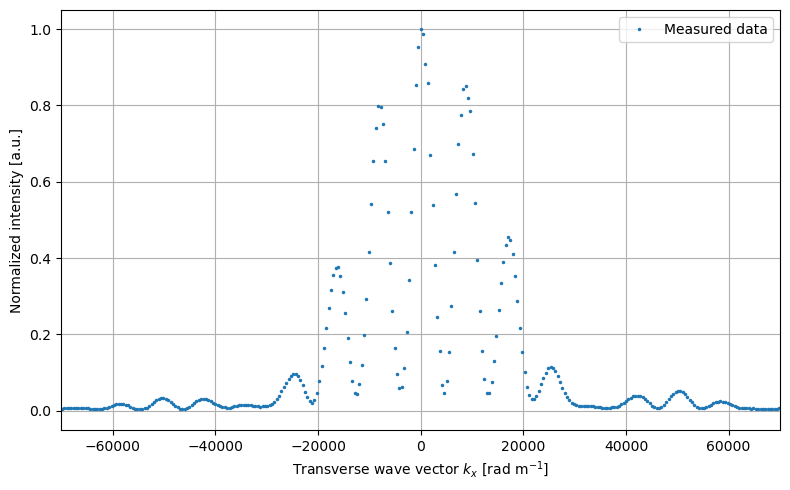

FFT coordinate spacing dx' = 0.006672 mm
FFT resolution uncertainty = 0.003336 mm


,Quantity,Value,Unit
0,Number of data points,2048.000000,-
1,Central maximum pixel,1125.000000,pixel
2,Background intensity,0.007352,a.u.
3,kx spacing,459.804224,rad/m
4,FFT coordinate spacing,0.000007,m
5,FFT resolution uncertainty,0.000003,m
6,b from FFT,0.000231,m
7,u(b) from FFT,0.000008,m
8,g from FFT,0.000740,m
9,u(g) from FFT,0.000025,m



Task 2c FFT results:
b_FFT = 0.231313 ± 0.008382 mm
g_FFT = 0.739821 ± 0.024820 mm

Comparison with manufacturer:
b_manufacturer = 0.200000 mm
relative deviation b = 15.656 %
g_manufacturer = 0.750000 mm
relative deviation g = 1.357 %

Comparison with previous tasks:
b_Task 2b = 0.184313 ± 0.006197 mm
relative difference b from Task 2b = 25.500 %
normalized difference b from Task 2b = 4.509
g_Task 2a = 0.759162 ± 0.026387 mm
relative difference g from Task 2a = 2.548 %
normalized difference g from Task 2a = 0.534
g_Task 2b = 0.734904 ± 0.024439 mm
relative difference g from Task 2b = 0.669 %
normalized difference g from Task 2b = 0.141


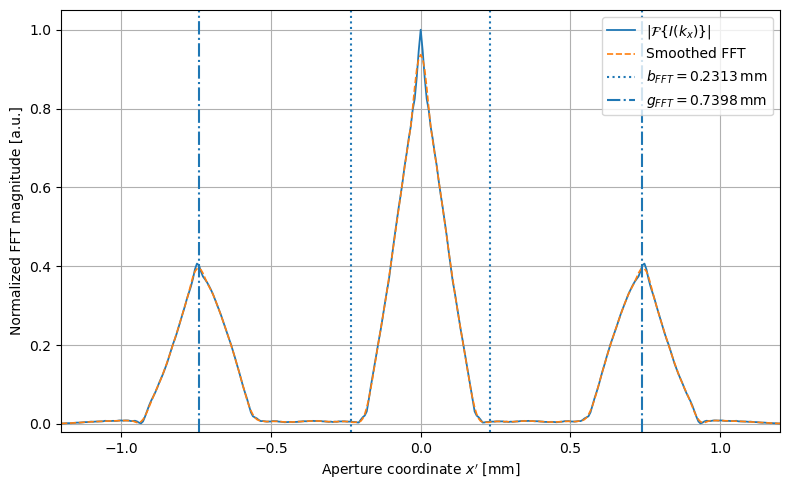

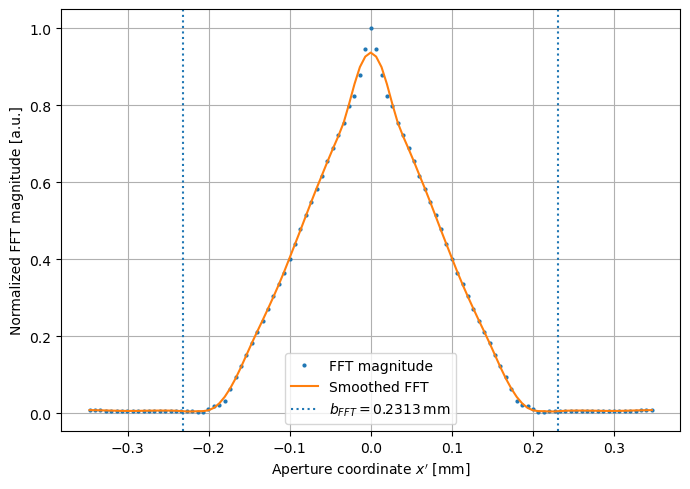

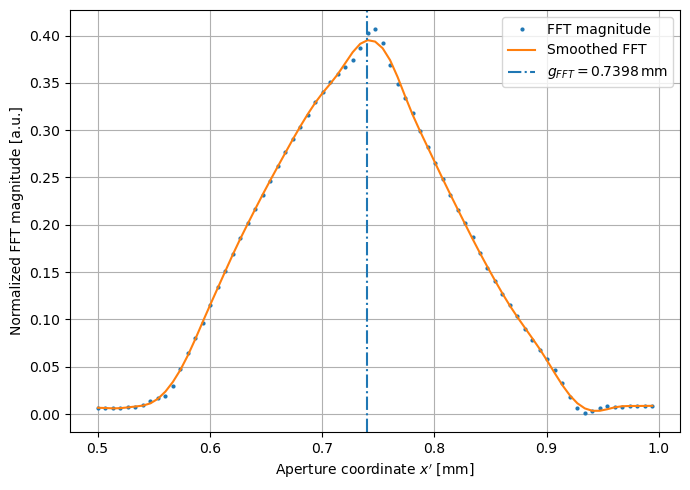

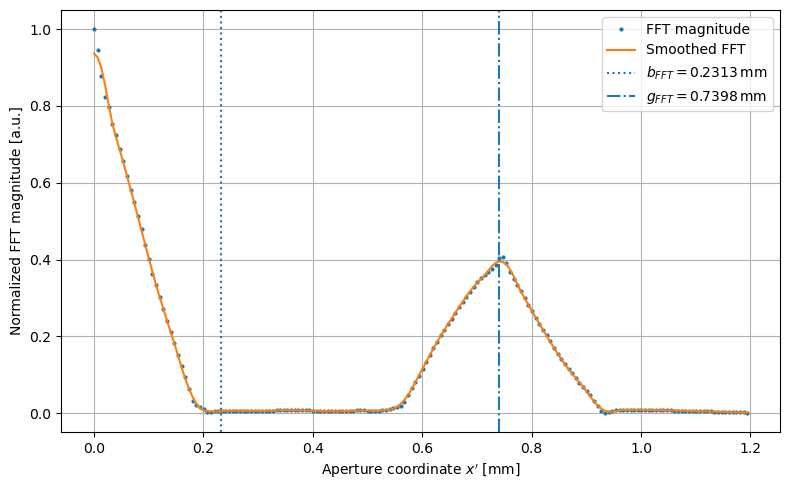


Saved files:
task2c_outputs\task2c_double_slit_intensity_kx.png
task2c_outputs\task2c_fft_double_slit.png
task2c_outputs\task2c_fft_double_slit_b_zoom.png
task2c_outputs\task2c_fft_double_slit_g_zoom.png
task2c_outputs\task2c_fft_double_slit_positive_side.png
task2c_outputs\task2c_fft_results.csv


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.signal import savgol_filter, find_peaks
from scipy.optimize import curve_fit

# ============================================================
# User inputs
# ============================================================

csv_path = Path("task 2a, b (2).csv")   # change path if needed

lambda_laser = 636e-9                   # m
u_lambda = 0.0                          # m, not specified

f = 300.8e-3                            # m
u_f = 10e-3                             # m

pixel_width = 14e-6                     # m, new CCD camera
u_pixel_width = 0.0                     # m, not specified

b_manufacturer = 0.200e-3               # m
g_manufacturer = 0.750e-3               # m

# Previous results for comparison
g_task2a = 0.759162e-3                  # m
u_g_task2a = 0.026387e-3                # m

b_task2b = 0.1843127e-3                 # m
u_b_task2b = 0.006197e-3                # m

g_task2b = 0.7349037e-3                 # m
u_g_task2b = 0.024439e-3                # m

# Background estimation
edge_points = 200

# FFT smoothing
savgol_window_fft = 11                  # must be odd
savgol_polyorder_fft = 3

# Expected search regions
b_search_min = 0.10e-3                  # m
b_search_max = 0.30e-3                  # m

g_search_min = 0.55e-3                  # m
g_search_max = 0.95e-3                  # m

# Plot ranges
kx_plot_limit = 7.0e4                   # rad/m
xprime_plot_limit_mm = 1.2              # mm

# Output folder
output_dir = Path("task2c_outputs")
output_dir.mkdir(exist_ok=True)

# ============================================================
# Load data
# ============================================================

data = np.loadtxt(csv_path, delimiter=",")
pixel = data[:, 0]
intensity = data[:, 1]

N = len(pixel)

# Central maximum
p0 = pixel[np.argmax(intensity)]

# Position axis
x = (pixel - p0) * pixel_width

# Exact kx axis
kx = (2 * np.pi / lambda_laser) * x / np.sqrt(x**2 + f**2)

# For FFT, the spacing must be uniform.
# The exact kx axis is almost uniform, but not perfectly uniform.
# Therefore, use the small-angle kx axis for the FFT.
# This is evenly spaced because x is evenly spaced.
kx_uniform = (2 * np.pi / lambda_laser) * x / f
dkx = np.mean(np.diff(kx_uniform))

# Background subtraction and normalization
I_bg = np.median(np.r_[intensity[:edge_points], intensity[-edge_points:]])
I_corr = intensity - I_bg
I_norm = I_corr / np.max(I_corr)

# Optional windowing:
# For the main extraction, no window is applied so the autocorrelation
# length scale remains directly interpretable.
I_for_fft = I_norm.copy()

print(f"Number of data points = {N}")
print(f"Central maximum pixel p0 = {p0:.0f}")
print(f"Maximum intensity = {np.max(intensity):.6f} a.u.")
print(f"Estimated background = {I_bg:.6f} a.u.")
print(f"kx spacing for FFT = {dkx:.6f} rad/m")

# ============================================================
# Plot 1: Fraunhofer double-slit intensity as a function of kx
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    kx_uniform,
    I_norm,
    marker=".",
    linestyle="None",
    markersize=3,
    label="Measured data"
)

plt.xlabel(r"Transverse wave vector $k_x$ [rad m$^{-1}$]")
plt.ylabel(r"Normalized intensity [a.u.]")
plt.xlim(-kx_plot_limit, kx_plot_limit)
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(output_dir / "task2c_double_slit_intensity_kx.png", dpi=300)
plt.show()

# ============================================================
# FFT calculation
# ============================================================

# Coordinate conjugate to kx.
# For FT convention exp(-i kx x'), the conjugate coordinate is:
# x' = 2*pi*fftfreq(N, d=dkx)
x_prime = 2 * np.pi * np.fft.fftshift(np.fft.fftfreq(N, d=dkx))  # m

fft_I = np.fft.fftshift(np.fft.fft(np.fft.ifftshift(I_for_fft))) * dkx
fft_mag = np.abs(fft_I)
fft_mag_norm = fft_mag / np.max(fft_mag)

# Smooth only for locating features
fft_mag_smooth = savgol_filter(fft_mag_norm, savgol_window_fft, savgol_polyorder_fft)

dx_prime = np.mean(np.diff(x_prime))
u_resolution = abs(dx_prime) / 2

print(f"FFT coordinate spacing dx' = {dx_prime*1e3:.6f} mm")
print(f"FFT resolution uncertainty = {u_resolution*1e3:.6f} mm")

# ============================================================
# Determine g from side autocorrelation peaks
# ============================================================

positive_mask = x_prime > 0
x_pos = x_prime[positive_mask]
fft_pos = fft_mag_norm[positive_mask]
fft_pos_smooth = fft_mag_smooth[positive_mask]

g_mask = (x_pos >= g_search_min) & (x_pos <= g_search_max)

if np.sum(g_mask) == 0:
    raise ValueError("No data points in g search window. Adjust g_search_min/g_search_max.")

g_indices = np.where(g_mask)[0]

# Side autocorrelation peak position near x' = g
g_index = g_indices[np.argmax(fft_pos_smooth[g_indices])]
g_fft = x_pos[g_index]

# Improve g estimate by fitting a parabola to the peak top
fit_half_width_points = 5
lo = max(g_index - fit_half_width_points, 0)
hi = min(g_index + fit_half_width_points + 1, len(x_pos))

x_peak_fit = x_pos[lo:hi]
y_peak_fit = fft_pos_smooth[lo:hi]

# Parabolic fit y = ax^2 + bx + c
coeff = np.polyfit(x_peak_fit, y_peak_fit, deg=2)
a_par, b_par, c_par = coeff

if a_par < 0:
    g_fft_parabolic = -b_par / (2 * a_par)
else:
    g_fft_parabolic = g_fft

# Use parabolic estimate if it lies in the search region
if g_search_min <= g_fft_parabolic <= g_search_max:
    g_fft = g_fft_parabolic

# ============================================================
# Determine b from width of central autocorrelation feature
# ============================================================

# The central feature is approximately triangular.
# For a double slit, the autocorrelation peak around x'=0 has half-width b.
# Therefore, the first minimum/edge near x'=b is used.
b_mask = (x_pos >= b_search_min) & (x_pos <= b_search_max)

if np.sum(b_mask) == 0:
    raise ValueError("No data points in b search window. Adjust b_search_min/b_search_max.")

b_indices = np.where(b_mask)[0]
b_index = b_indices[np.argmin(fft_pos_smooth[b_indices])]
b_fft = x_pos[b_index]

# Optional local parabolic refinement of the minimum
lo = max(b_index - fit_half_width_points, 0)
hi = min(b_index + fit_half_width_points + 1, len(x_pos))

x_min_fit = x_pos[lo:hi]
y_min_fit = fft_pos_smooth[lo:hi]

coeff_min = np.polyfit(x_min_fit, y_min_fit, deg=2)
a_min, b_min_coef, c_min = coeff_min

if a_min > 0:
    b_fft_parabolic = -b_min_coef / (2 * a_min)
else:
    b_fft_parabolic = b_fft

if b_search_min <= b_fft_parabolic <= b_search_max:
    b_fft = b_fft_parabolic

# ============================================================
# Uncertainty calculation
# ============================================================

# Scale uncertainty of FFT coordinate:
# x' scale depends approximately on lambda*f/pixel_width.
relative_scale_uncertainty = np.sqrt(
    (u_f / f)**2
    + (u_lambda / lambda_laser)**2
    + (u_pixel_width / pixel_width)**2
)

u_b_scale = b_fft * relative_scale_uncertainty
u_g_scale = g_fft * relative_scale_uncertainty

# Include FFT resolution
u_b_fft = np.sqrt(u_resolution**2 + u_b_scale**2)
u_g_fft = np.sqrt(u_resolution**2 + u_g_scale**2)

# Comparisons
relative_dev_b_man = abs(b_fft - b_manufacturer) / b_manufacturer * 100
relative_dev_g_man = abs(g_fft - g_manufacturer) / g_manufacturer * 100

relative_diff_b_task2b = abs(b_fft - b_task2b) / b_task2b * 100
relative_diff_g_task2a = abs(g_fft - g_task2a) / g_task2a * 100
relative_diff_g_task2b = abs(g_fft - g_task2b) / g_task2b * 100

combined_u_b_task2b = np.sqrt(u_b_fft**2 + u_b_task2b**2)
combined_u_g_task2a = np.sqrt(u_g_fft**2 + u_g_task2a**2)
combined_u_g_task2b = np.sqrt(u_g_fft**2 + u_g_task2b**2)

normalized_diff_b_task2b = abs(b_fft - b_task2b) / combined_u_b_task2b
normalized_diff_g_task2a = abs(g_fft - g_task2a) / combined_u_g_task2a
normalized_diff_g_task2b = abs(g_fft - g_task2b) / combined_u_g_task2b

# ============================================================
# Results table
# ============================================================

results_table = pd.DataFrame({
    "Quantity": [
        "Number of data points",
        "Central maximum pixel",
        "Background intensity",
        "kx spacing",
        "FFT coordinate spacing",
        "FFT resolution uncertainty",
        "b from FFT",
        "u(b) from FFT",
        "g from FFT",
        "u(g) from FFT",
        "b manufacturer",
        "g manufacturer",
        "relative deviation b from manufacturer",
        "relative deviation g from manufacturer",
        "b from Task 2b",
        "u(b) from Task 2b",
        "relative difference b from Task 2b",
        "normalized difference b from Task 2b",
        "g from Task 2a",
        "u(g) from Task 2a",
        "relative difference g from Task 2a",
        "normalized difference g from Task 2a",
        "g from Task 2b",
        "u(g) from Task 2b",
        "relative difference g from Task 2b",
        "normalized difference g from Task 2b"
    ],
    "Value": [
        N,
        p0,
        I_bg,
        dkx,
        dx_prime,
        u_resolution,
        b_fft,
        u_b_fft,
        g_fft,
        u_g_fft,
        b_manufacturer,
        g_manufacturer,
        relative_dev_b_man,
        relative_dev_g_man,
        b_task2b,
        u_b_task2b,
        relative_diff_b_task2b,
        normalized_diff_b_task2b,
        g_task2a,
        u_g_task2a,
        relative_diff_g_task2a,
        normalized_diff_g_task2a,
        g_task2b,
        u_g_task2b,
        relative_diff_g_task2b,
        normalized_diff_g_task2b
    ],
    "Unit": [
        "-",
        "pixel",
        "a.u.",
        "rad/m",
        "m",
        "m",
        "m",
        "m",
        "m",
        "m",
        "m",
        "m",
        "%",
        "%",
        "m",
        "m",
        "%",
        "standard uncertainties",
        "m",
        "m",
        "%",
        "standard uncertainties",
        "m",
        "m",
        "%",
        "standard uncertainties"
    ]
})

display(results_table)

print("\nTask 2c FFT results:")
print(f"b_FFT = {b_fft*1e3:.6f} ± {u_b_fft*1e3:.6f} mm")
print(f"g_FFT = {g_fft*1e3:.6f} ± {u_g_fft*1e3:.6f} mm")

print("\nComparison with manufacturer:")
print(f"b_manufacturer = {b_manufacturer*1e3:.6f} mm")
print(f"relative deviation b = {relative_dev_b_man:.3f} %")
print(f"g_manufacturer = {g_manufacturer*1e3:.6f} mm")
print(f"relative deviation g = {relative_dev_g_man:.3f} %")

print("\nComparison with previous tasks:")
print(f"b_Task 2b = {b_task2b*1e3:.6f} ± {u_b_task2b*1e3:.6f} mm")
print(f"relative difference b from Task 2b = {relative_diff_b_task2b:.3f} %")
print(f"normalized difference b from Task 2b = {normalized_diff_b_task2b:.3f}")

print(f"g_Task 2a = {g_task2a*1e3:.6f} ± {u_g_task2a*1e3:.6f} mm")
print(f"relative difference g from Task 2a = {relative_diff_g_task2a:.3f} %")
print(f"normalized difference g from Task 2a = {normalized_diff_g_task2a:.3f}")

print(f"g_Task 2b = {g_task2b*1e3:.6f} ± {u_g_task2b*1e3:.6f} mm")
print(f"relative difference g from Task 2b = {relative_diff_g_task2b:.3f} %")
print(f"normalized difference g from Task 2b = {normalized_diff_g_task2b:.3f}")

# ============================================================
# Plot 2: FFT magnitude as function of aperture coordinate
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    x_prime * 1e3,
    fft_mag_norm,
    linestyle="-",
    linewidth=1.3,
    label=r"$|\mathcal{F}\{I(k_x)\}|$"
)

plt.plot(
    x_prime * 1e3,
    fft_mag_smooth,
    linestyle="--",
    linewidth=1.2,
    label="Smoothed FFT"
)

plt.axvline(b_fft * 1e3, linestyle=":", linewidth=1.5,
            label=rf"$b_{{FFT}}={b_fft*1e3:.4f}\,\mathrm{{mm}}$")
plt.axvline(-b_fft * 1e3, linestyle=":", linewidth=1.5)

plt.axvline(g_fft * 1e3, linestyle="-.", linewidth=1.5,
            label=rf"$g_{{FFT}}={g_fft*1e3:.4f}\,\mathrm{{mm}}$")
plt.axvline(-g_fft * 1e3, linestyle="-.", linewidth=1.5)

plt.xlabel(r"Aperture coordinate $x'$ [mm]")
plt.ylabel(r"Normalized FFT magnitude [a.u.]")
plt.xlim(-xprime_plot_limit_mm, xprime_plot_limit_mm)
plt.ylim(-0.02, 1.05)
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(output_dir / "task2c_fft_double_slit.png", dpi=300)
plt.show()

# ============================================================
# Plot 3: Zoom near central autocorrelation feature for b
# ============================================================

plt.figure(figsize=(7, 5))

zoom_b_mask = (x_prime >= -0.35e-3) & (x_prime <= 0.35e-3)

plt.plot(
    x_prime[zoom_b_mask] * 1e3,
    fft_mag_norm[zoom_b_mask],
    marker=".",
    linestyle="None",
    markersize=4,
    label="FFT magnitude"
)

plt.plot(
    x_prime[zoom_b_mask] * 1e3,
    fft_mag_smooth[zoom_b_mask],
    linestyle="-",
    linewidth=1.5,
    label="Smoothed FFT"
)

plt.axvline(b_fft * 1e3, linestyle=":", linewidth=1.5,
            label=rf"$b_{{FFT}}={b_fft*1e3:.4f}\,\mathrm{{mm}}$")
plt.axvline(-b_fft * 1e3, linestyle=":", linewidth=1.5)

plt.xlabel(r"Aperture coordinate $x'$ [mm]")
plt.ylabel(r"Normalized FFT magnitude [a.u.]")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(output_dir / "task2c_fft_double_slit_b_zoom.png", dpi=300)
plt.show()

# ============================================================
# Plot 4: Zoom near positive side autocorrelation peak for g
# ============================================================

plt.figure(figsize=(7, 5))

zoom_g_mask = (x_prime >= 0.50e-3) & (x_prime <= 1.00e-3)

plt.plot(
    x_prime[zoom_g_mask] * 1e3,
    fft_mag_norm[zoom_g_mask],
    marker=".",
    linestyle="None",
    markersize=4,
    label="FFT magnitude"
)

plt.plot(
    x_prime[zoom_g_mask] * 1e3,
    fft_mag_smooth[zoom_g_mask],
    linestyle="-",
    linewidth=1.5,
    label="Smoothed FFT"
)

plt.axvline(g_fft * 1e3, linestyle="-.", linewidth=1.5,
            label=rf"$g_{{FFT}}={g_fft*1e3:.4f}\,\mathrm{{mm}}$")

plt.xlabel(r"Aperture coordinate $x'$ [mm]")
plt.ylabel(r"Normalized FFT magnitude [a.u.]")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(output_dir / "task2c_fft_double_slit_g_zoom.png", dpi=300)
plt.show()

# ============================================================
# Plot 5: FFT coordinate with positive side only
# ============================================================

plt.figure(figsize=(8, 5))

positive_plot_mask = (x_prime >= 0) & (x_prime <= 1.2e-3)

plt.plot(
    x_prime[positive_plot_mask] * 1e3,
    fft_mag_norm[positive_plot_mask],
    marker=".",
    linestyle="None",
    markersize=4,
    label="FFT magnitude"
)

plt.plot(
    x_prime[positive_plot_mask] * 1e3,
    fft_mag_smooth[positive_plot_mask],
    linestyle="-",
    linewidth=1.5,
    label="Smoothed FFT"
)

plt.axvline(b_fft * 1e3, linestyle=":", linewidth=1.5,
            label=rf"$b_{{FFT}}={b_fft*1e3:.4f}\,\mathrm{{mm}}$")
plt.axvline(g_fft * 1e3, linestyle="-.", linewidth=1.5,
            label=rf"$g_{{FFT}}={g_fft*1e3:.4f}\,\mathrm{{mm}}$")

plt.xlabel(r"Aperture coordinate $x'$ [mm]")
plt.ylabel(r"Normalized FFT magnitude [a.u.]")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(output_dir / "task2c_fft_double_slit_positive_side.png", dpi=300)
plt.show()

# ============================================================
# Save table
# ============================================================

results_table.to_csv(output_dir / "task2c_fft_results.csv", index=False)

print("\nSaved files:")
for file in sorted(output_dir.glob("*")):
    print(file)

,Distance label,z [cm],u(z) [cm],central pixel p0,background [a.u.],noise estimate u(I) [norm. a.u.],Fresnel number N_b,u(N_b),Fresnel number N_g,u(N_g),A,u(A),C,u(C),x0 [mm],u(x0) [mm],RMSE [norm. a.u.],R^2
0,40 cm,40.0,0.5,890.0,0.003952,0.001030,0.033384,0.002283,0.530742,0.035917,1.119790,0.009096,0.008274,0.001067,0.006783,0.000828,0.046610,0.882509
1,50 cm,50.0,0.5,904.0,0.005709,0.002070,0.026707,0.001816,0.424594,0.028557,1.049378,0.003589,0.007466,0.000458,0.001514,0.000417,0.019920,0.976646
2,60 cm,60.0,0.5,924.0,0.004423,0.001607,0.022256,0.001508,0.353828,0.023717,1.052116,0.006009,0.005402,0.000828,0.010266,0.000813,0.035853,0.937560


Input parameters from Task 2b:
b = 0.184313 ± 0.006197 mm
g = 0.734904 ± 0.024439 mm

Distance uncertainty used:
u(z) = 0.500 cm

Pixel and centering uncertainty:
pixel width = 14.000 µm
u(center) = 2 pixels = 28.000 µm


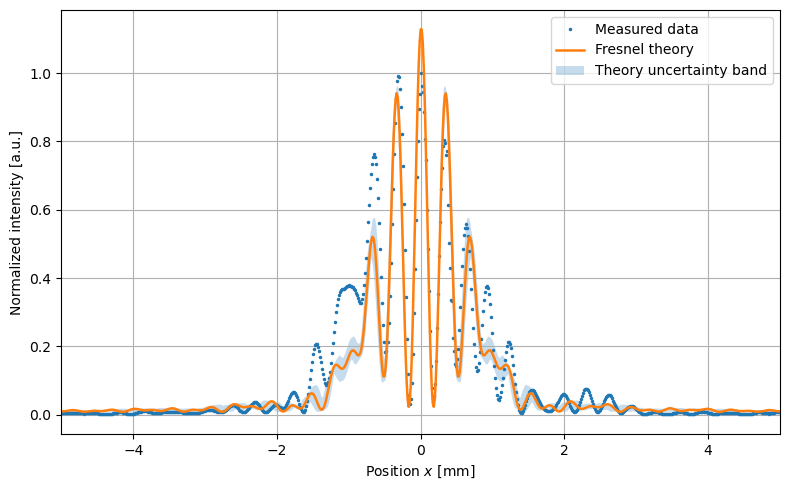

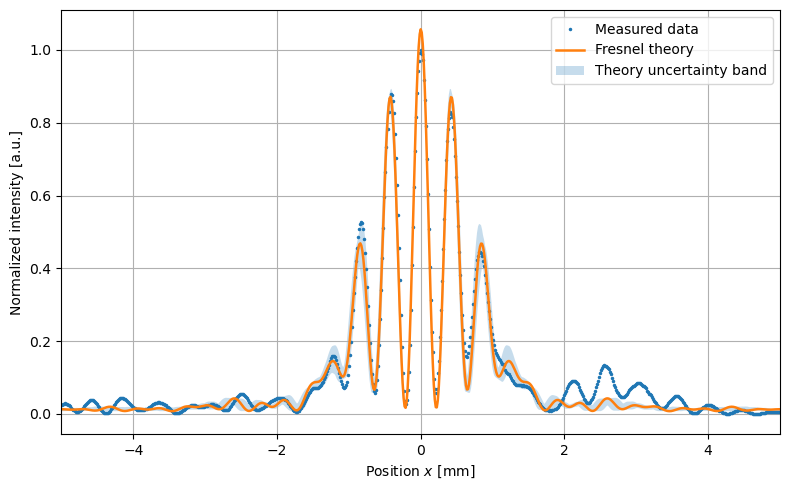

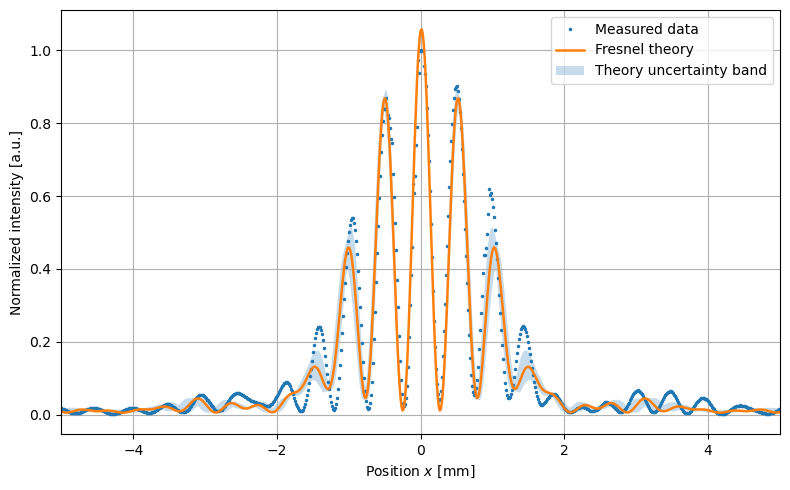

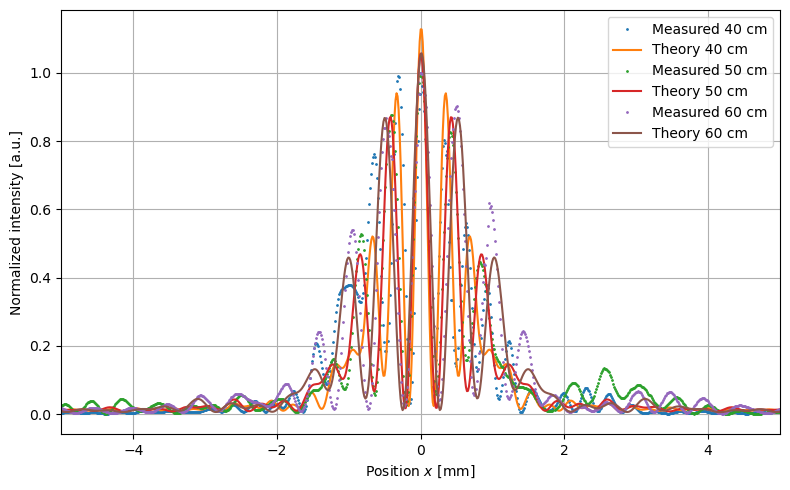

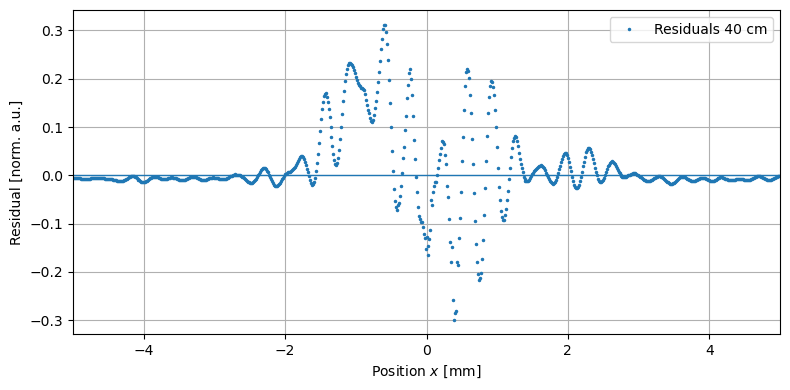

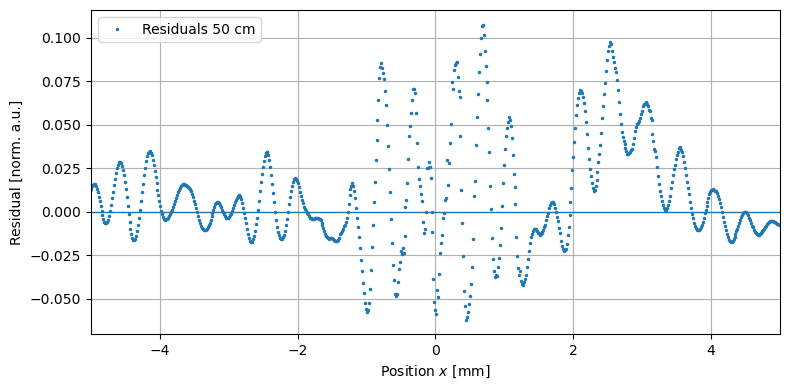

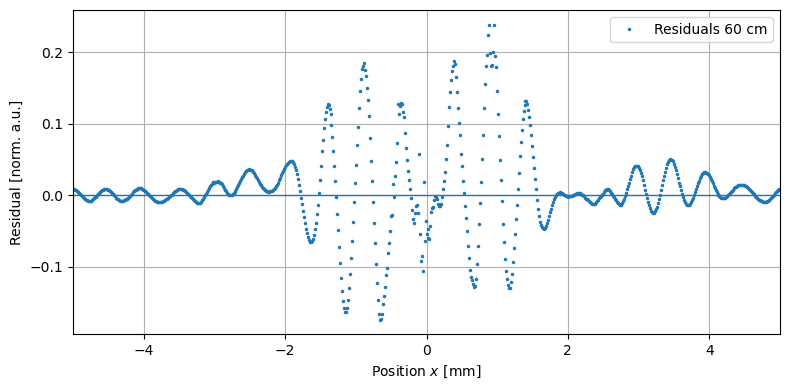

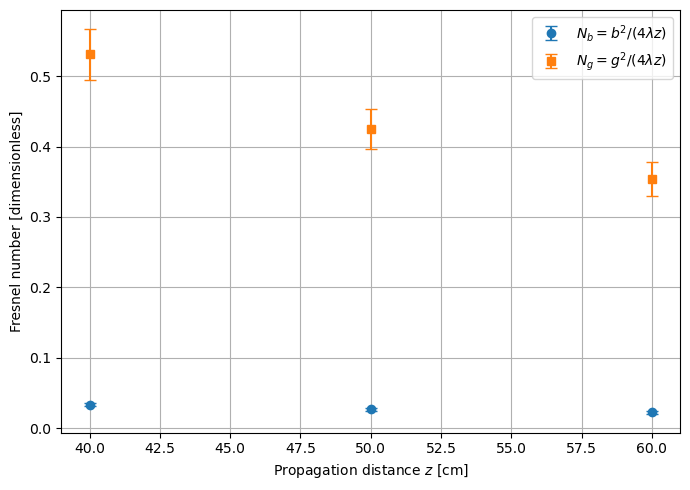


Saved files:
task2d_outputs\task2d_all_fresnel_profiles.png
task2d_outputs\task2d_fresnel_numbers_vs_distance.png
task2d_outputs\task2d_fresnel_profile_40_cm.png
task2d_outputs\task2d_fresnel_profile_50_cm.png
task2d_outputs\task2d_fresnel_profile_60_cm.png
task2d_outputs\task2d_residuals_40_cm.png
task2d_outputs\task2d_residuals_50_cm.png
task2d_outputs\task2d_residuals_60_cm.png
task2d_outputs\task2d_summary_table.csv


In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.special import fresnel
from scipy.optimize import curve_fit

# ============================================================
# User inputs
# ============================================================

files = {
    "40 cm": {
        "path": Path("task 2c 40cm.csv"),
        "z": 40e-2
    },
    "50 cm": {
        "path": Path("task 2c 50cm.csv"),
        "z": 50e-2
    },
    "60 cm": {
        "path": Path("task 2c 60cm.csv"),
        "z": 60e-2
    }
}

lambda_laser = 636e-9              # m
u_lambda = 0.0                     # m, not specified

pixel_width = 14e-6                # m, new CCD camera
u_pixel_width = 0.0                # m, not specified

# Use Task 2b fitted parameters
b = 0.1843127e-3                   # m
u_b = 0.006197e-3                  # m

g = 0.7349037e-3                   # m
u_g = 0.024439e-3                  # m

# Distance uncertainty
u_z = 0.5e-2                       # m = 0.5 cm

# Uncertainty in locating profile center
u_center_pixel = 2                 # pixels

# Background estimation
edge_points = 200

# Plot range
x_plot_limit_mm = 5.0

# Output folder
output_dir = Path("task2d_outputs")
output_dir.mkdir(exist_ok=True)

# ============================================================
# Fresnel theory functions
# ============================================================

def complex_fresnel_F(u):
    """
    scipy.special.fresnel returns S(u), C(u).
    The complex Fresnel integral used here is F(u) = C(u) + i S(u).
    """
    S, C = fresnel(u)
    return C + 1j * S


def double_slit_fresnel_intensity(x, z, b, g, wavelength):
    """
    Double-slit Fresnel diffraction intensity.

    I(x,z) ∝ | F((g+b+2x)/sqrt(2 lambda z))
              + F((g+b-2x)/sqrt(2 lambda z))
              - F((g-b+2x)/sqrt(2 lambda z))
              - F((g-b-2x)/sqrt(2 lambda z)) |^2
    """
    denom = np.sqrt(2 * wavelength * z)

    u1 = (g + b + 2 * x) / denom
    u2 = (g + b - 2 * x) / denom
    u3 = (g - b + 2 * x) / denom
    u4 = (g - b - 2 * x) / denom

    field = (
        complex_fresnel_F(u1)
        + complex_fresnel_F(u2)
        - complex_fresnel_F(u3)
        - complex_fresnel_F(u4)
    )

    intensity = np.abs(field)**2
    return intensity


def normalized_theory(x, z, b, g, wavelength):
    """
    Background-free normalized Fresnel theory curve.
    """
    I = double_slit_fresnel_intensity(x, z, b, g, wavelength)
    return I / np.max(I)


def fit_model(x, A, C, x0, z, b, g, wavelength):
    """
    Fit model for measured normalized intensity.

    A  = amplitude scale
    C  = vertical offset
    x0 = horizontal offset
    """
    return A * normalized_theory(x - x0, z, b, g, wavelength) + C


def rmse(y, yfit):
    return np.sqrt(np.mean((y - yfit)**2))


def r_squared(y, yfit):
    ss_res = np.sum((y - yfit)**2)
    ss_tot = np.sum((y - np.mean(y))**2)
    return 1 - ss_res / ss_tot


# ============================================================
# Analysis loop
# ============================================================

summary_rows = []
processed = {}

for label, info in files.items():

    path = info["path"]
    z = info["z"]

    # --------------------------------------------------------
    # Load data
    # --------------------------------------------------------

    data = np.loadtxt(path, delimiter=",")
    pixel = data[:, 0]
    intensity = data[:, 1]

    N = len(pixel)

    # Central maximum
    p0 = pixel[np.argmax(intensity)]

    # Position axis centered at the maximum
    x = (pixel - p0) * pixel_width

    # Background correction and normalization
    I_bg = np.median(np.r_[intensity[:edge_points], intensity[-edge_points:]])
    I_corr = intensity - I_bg
    I_norm = I_corr / np.max(I_corr)

    # Estimate intensity noise from background regions after normalization
    bg_norm = np.r_[I_norm[:edge_points], I_norm[-edge_points:]]
    u_I = np.std(bg_norm)

    # Fresnel numbers
    N_b = b**2 / (4 * lambda_laser * z)
    N_g = g**2 / (4 * lambda_laser * z)

    u_N_b = N_b * np.sqrt(
        (2 * u_b / b)**2
        + (u_lambda / lambda_laser)**2
        + (u_z / z)**2
    )

    u_N_g = N_g * np.sqrt(
        (2 * u_g / g)**2
        + (u_lambda / lambda_laser)**2
        + (u_z / z)**2
    )

    # --------------------------------------------------------
    # Fit scale, vertical offset, and horizontal offset.
    # b, g, and z are kept fixed to measured/fitted values.
    # --------------------------------------------------------

    def model_for_curve_fit(xdata, A, C, x0):
        return fit_model(xdata, A, C, x0, z, b, g, lambda_laser)

    initial_guess = [1.0, 0.0, 0.0]

    # Allow small horizontal shifts
    x0_bound = 30 * pixel_width

    bounds = (
        [0.0, -0.5, -x0_bound],
        [2.0,  0.5,  x0_bound]
    )

    popt, pcov = curve_fit(
        model_for_curve_fit,
        x,
        I_norm,
        p0=initial_guess,
        bounds=bounds,
        maxfev=50000
    )

    A_fit, C_fit, x0_fit = popt
    u_A_fit, u_C_fit, u_x0_fit = np.sqrt(np.diag(pcov))

    I_fit = model_for_curve_fit(x, A_fit, C_fit, x0_fit)
    residuals = I_norm - I_fit

    RMSE = rmse(I_norm, I_fit)
    R2 = r_squared(I_norm, I_fit)

    # --------------------------------------------------------
    # Theory uncertainty band from b, g, and z uncertainties
    # --------------------------------------------------------

    theory_curves = []

    for b_i in [b - u_b, b, b + u_b]:
        for g_i in [g - u_g, g, g + u_g]:
            for z_i in [z - u_z, z, z + u_z]:
                if b_i > 0 and g_i > b_i and z_i > 0:
                    theory_curves.append(
                        fit_model(x, A_fit, C_fit, x0_fit, z_i, b_i, g_i, lambda_laser)
                    )

    theory_curves = np.array(theory_curves)
    theory_lower = np.min(theory_curves, axis=0)
    theory_upper = np.max(theory_curves, axis=0)

    # --------------------------------------------------------
    # Store results
    # --------------------------------------------------------

    processed[label] = {
        "pixel": pixel,
        "intensity": intensity,
        "x": x,
        "I_norm": I_norm,
        "I_fit": I_fit,
        "residuals": residuals,
        "theory_lower": theory_lower,
        "theory_upper": theory_upper,
        "p0": p0,
        "z": z,
        "I_bg": I_bg,
        "u_I": u_I,
        "N_b": N_b,
        "u_N_b": u_N_b,
        "N_g": N_g,
        "u_N_g": u_N_g,
        "A_fit": A_fit,
        "u_A_fit": u_A_fit,
        "C_fit": C_fit,
        "u_C_fit": u_C_fit,
        "x0_fit": x0_fit,
        "u_x0_fit": u_x0_fit,
        "RMSE": RMSE,
        "R2": R2
    }

    summary_rows.append({
        "Distance label": label,
        "z [cm]": z * 100,
        "u(z) [cm]": u_z * 100,
        "central pixel p0": p0,
        "background [a.u.]": I_bg,
        "noise estimate u(I) [norm. a.u.]": u_I,
        "Fresnel number N_b": N_b,
        "u(N_b)": u_N_b,
        "Fresnel number N_g": N_g,
        "u(N_g)": u_N_g,
        "A": A_fit,
        "u(A)": u_A_fit,
        "C": C_fit,
        "u(C)": u_C_fit,
        "x0 [mm]": x0_fit * 1e3,
        "u(x0) [mm]": u_x0_fit * 1e3,
        "RMSE [norm. a.u.]": RMSE,
        "R^2": R2
    })


summary_table = pd.DataFrame(summary_rows)
display(summary_table)

print("Input parameters from Task 2b:")
print(f"b = {b*1e3:.6f} ± {u_b*1e3:.6f} mm")
print(f"g = {g*1e3:.6f} ± {u_g*1e3:.6f} mm")

print("\nDistance uncertainty used:")
print(f"u(z) = {u_z*100:.3f} cm")

print("\nPixel and centering uncertainty:")
print(f"pixel width = {pixel_width*1e6:.3f} µm")
print(f"u(center) = {u_center_pixel} pixels = {u_center_pixel*pixel_width*1e6:.3f} µm")

# ============================================================
# Plot 1: Each Fresnel profile with corresponding theory curve
# ============================================================

for label, result in processed.items():

    x_mm = result["x"] * 1e3

    plt.figure(figsize=(8, 5))

    plt.plot(
        x_mm,
        result["I_norm"],
        marker=".",
        linestyle="None",
        markersize=3,
        label="Measured data"
    )

    plt.plot(
        x_mm,
        result["I_fit"],
        linestyle="-",
        linewidth=1.8,
        label="Fresnel theory"
    )

    plt.fill_between(
        x_mm,
        result["theory_lower"],
        result["theory_upper"],
        alpha=0.25,
        label="Theory uncertainty band"
    )

    plt.xlabel(r"Position $x$ [mm]")
    plt.ylabel(r"Normalized intensity [a.u.]")
    plt.xlim(-x_plot_limit_mm, x_plot_limit_mm)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    save_name = f"task2d_fresnel_profile_{label.replace(' ', '_')}.png"
    plt.savefig(output_dir / save_name, dpi=300)
    plt.show()

# ============================================================
# Plot 2: All three Fresnel profiles compared in one plot
# ============================================================

plt.figure(figsize=(8, 5))

for label, result in processed.items():

    x_mm = result["x"] * 1e3

    plt.plot(
        x_mm,
        result["I_norm"],
        marker=".",
        linestyle="None",
        markersize=2,
        label=f"Measured {label}"
    )

    plt.plot(
        x_mm,
        result["I_fit"],
        linestyle="-",
        linewidth=1.5,
        label=f"Theory {label}"
    )

plt.xlabel(r"Position $x$ [mm]")
plt.ylabel(r"Normalized intensity [a.u.]")
plt.xlim(-x_plot_limit_mm, x_plot_limit_mm)
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(output_dir / "task2d_all_fresnel_profiles.png", dpi=300)
plt.show()

# ============================================================
# Plot 3: Residuals for each distance
# ============================================================

for label, result in processed.items():

    x_mm = result["x"] * 1e3

    plt.figure(figsize=(8, 4))

    plt.axhline(0, linestyle="-", linewidth=1)

    plt.plot(
        x_mm,
        result["residuals"],
        marker=".",
        linestyle="None",
        markersize=3,
        label=f"Residuals {label}"
    )

    plt.xlabel(r"Position $x$ [mm]")
    plt.ylabel(r"Residual [norm. a.u.]")
    plt.xlim(-x_plot_limit_mm, x_plot_limit_mm)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    save_name = f"task2d_residuals_{label.replace(' ', '_')}.png"
    plt.savefig(output_dir / save_name, dpi=300)
    plt.show()

# ============================================================
# Plot 4: Fresnel numbers versus distance
# ============================================================

z_values_cm = np.array([processed[label]["z"] * 100 for label in processed])
N_b_values = np.array([processed[label]["N_b"] for label in processed])
u_N_b_values = np.array([processed[label]["u_N_b"] for label in processed])
N_g_values = np.array([processed[label]["N_g"] for label in processed])
u_N_g_values = np.array([processed[label]["u_N_g"] for label in processed])

plt.figure(figsize=(7, 5))

plt.errorbar(
    z_values_cm,
    N_b_values,
    yerr=u_N_b_values,
    fmt="o",
    capsize=4,
    label=r"$N_b=b^2/(4\lambda z)$"
)

plt.errorbar(
    z_values_cm,
    N_g_values,
    yerr=u_N_g_values,
    fmt="s",
    capsize=4,
    label=r"$N_g=g^2/(4\lambda z)$"
)

plt.xlabel(r"Propagation distance $z$ [cm]")
plt.ylabel(r"Fresnel number [dimensionless]")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(output_dir / "task2d_fresnel_numbers_vs_distance.png", dpi=300)
plt.show()

# ============================================================
# Save summary table
# ============================================================

summary_table.to_csv(output_dir / "task2d_summary_table.csv", index=False)

print("\nSaved files:")
for file in sorted(output_dir.glob("*.png")):
    print(file)
print(output_dir / "task2d_summary_table.csv")

,Distance label,z [cm],u(z) [cm],central pixel p0,background [a.u.],first peak kappa_1 [1/m],u(kappa_1) [1/m],first peak k_1 [rad/m],g from first peak [mm],u(g) [mm],first peak amplitude [a.u. m],u(amplitude) [a.u. m]
0,22 cm,22.0,0.5,997.0,0.003601,3905.051541,17.438616,24536.162469,0.256079,0.001144,0.000743,0.000065
1,24 cm,24.0,0.5,1054.0,0.003605,3862.705579,17.438616,24270.094937,0.258886,0.001169,0.000454,0.000072
2,26 cm,26.0,0.5,1007.0,0.003925,4020.772669,17.438616,25263.259757,0.248708,0.001079,0.000258,0.000112
3,28 cm,28.0,0.5,903.0,0.003715,3949.307682,17.438616,24814.232000,0.253209,0.001118,0.000529,0.000041
4,30 cm,30.0,0.5,1011.0,0.003736,3940.935770,17.438616,24761.629729,0.253747,0.001123,0.000719,0.000052
5,32 cm,32.0,0.5,999.0,0.004188,3872.956108,17.438616,24334.500913,0.258201,0.001163,0.000721,0.000062
6,34 cm,34.0,0.5,1001.0,0.004536,3819.132826,17.438616,23996.319261,0.261840,0.001196,0.000466,0.000050
7,36 cm,36.0,0.5,921.0,0.004605,3485.869108,17.438616,21902.361563,0.286873,0.001435,0.000349,0.000102
8,38 cm,38.0,0.5,999.0,0.005271,3954.083993,17.438616,24844.242448,0.252903,0.001115,0.000479,0.000040
9,40 cm,40.0,0.5,1002.0,0.004318,3922.975114,17.438616,24648.779595,0.254909,0.001133,0.000557,0.000043



Grating constant from FFT first-order peaks:
g_mean = 0.258684 ± 0.002100 mm
g_manufacturer = 0.250000 mm
lines/cm manufacturer = 40.0
relative deviation from manufacturer = 3.473 %

Talbot analysis:
Expected t_B from manufacturer = 19.654088 cm
Expected first-peak amplitude period t_B/2 = 9.827044 cm
Fitted amplitude period Delta z = 10.775529 ± 0.515500 cm
Experimental Talbot length t_B = 21.551059 ± 1.030999 cm
Theoretical t_B from measured g = 21.043164 ± 0.341634 cm
Relative deviation from manufacturer t_B = 9.652 %
Relative deviation from measured-g t_B = 2.414 %
Normalized difference from measured-g t_B = 0.468

Fit quality for first-peak amplitude:
RMSE = 0.072622
R^2  = 0.869102


,Quantity,Value,Unit
0,manufacturer lines per cm,40.000000,lines/cm
1,manufacturer grating constant,0.000250,m
2,measured grating constant from FFT,0.000259,m
3,u(measured grating constant),0.000002,m
4,relative deviation of g from manufacturer,3.473484,%
5,theoretical Talbot length from manufacturer g,0.196541,m
6,theoretical Talbot length from measured g,0.210432,m
7,u(theoretical Talbot length from measured g),0.003416,m
8,fitted first-peak amplitude period,0.107755,m
9,u(fitted first-peak amplitude period),0.005155,m


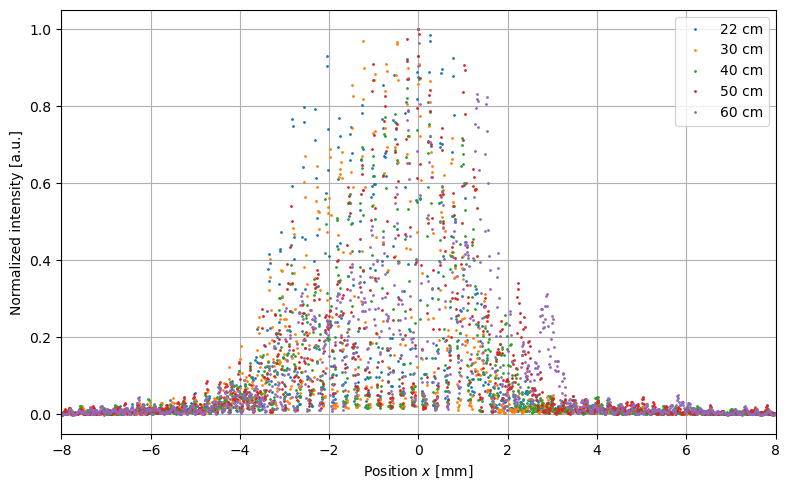

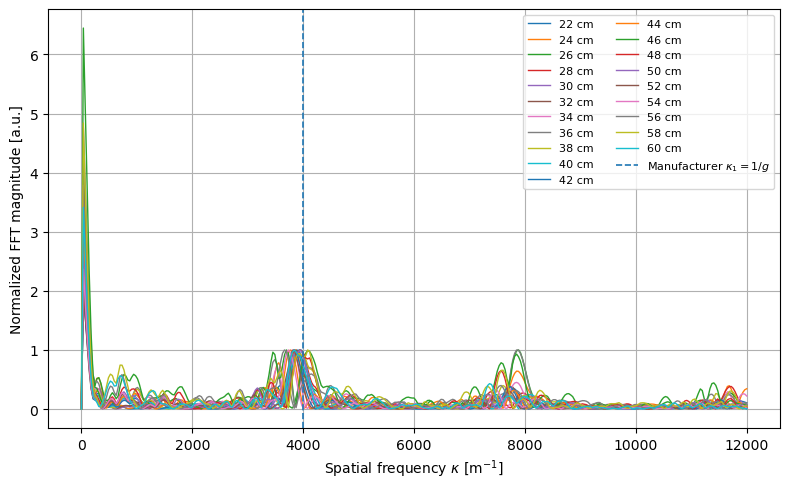

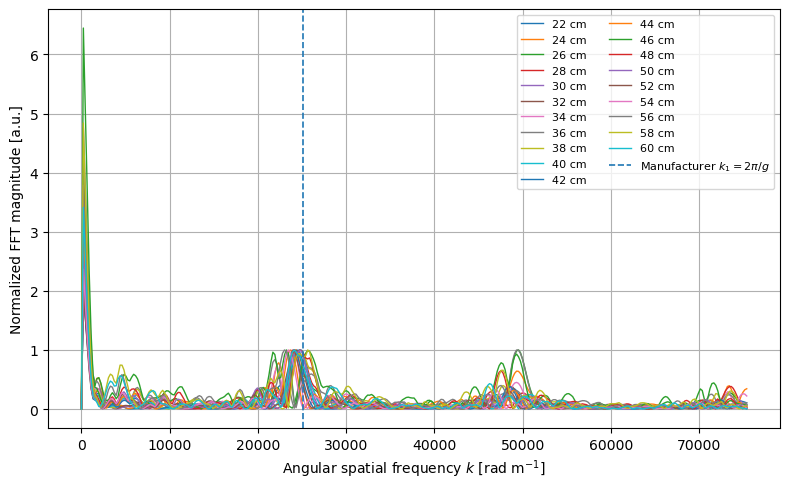

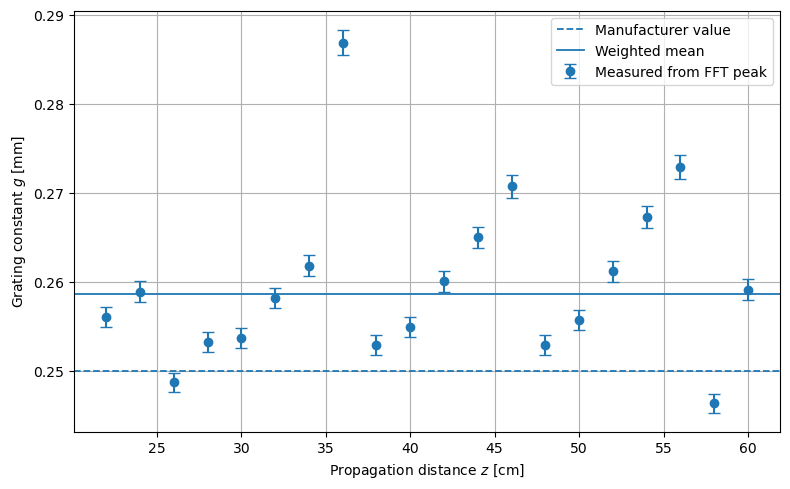

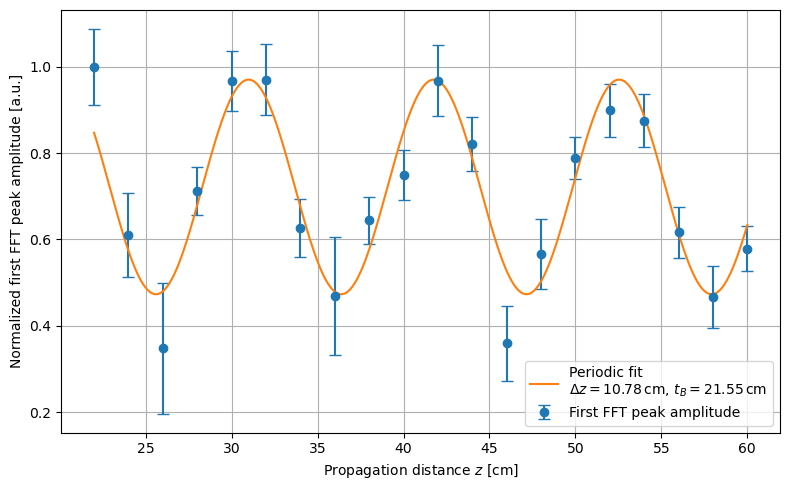

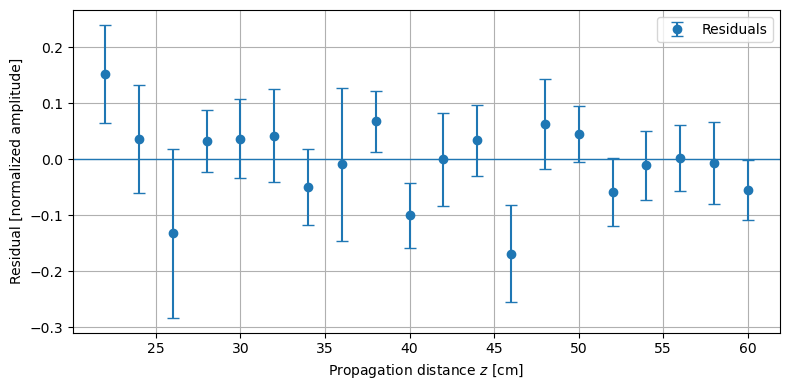


Saved files:
task3_outputs\.ipynb_checkpoints
task3_outputs\task3_example_grating_profiles.png
task3_outputs\task3_fft_peak_table.csv
task3_outputs\task3_fft_profiles_k.png
task3_outputs\task3_fft_profiles_kappa.png
task3_outputs\task3_first_peak_amplitude_residuals.png
task3_outputs\task3_first_peak_amplitude_vs_distance.png
task3_outputs\task3_grating_constant_vs_distance.png
task3_outputs\task3_results_summary.csv


In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.signal import find_peaks, savgol_filter
from scipy.optimize import curve_fit

# ============================================================
# User inputs
# ============================================================

files = {
    "22 cm": {"path": Path("task 3 22cm.csv"), "z": 22e-2},
    "24 cm": {"path": Path("task 3 24cm.csv"), "z": 24e-2},
    "26 cm": {"path": Path("task 3 26cm.csv"), "z": 26e-2},
    "28 cm": {"path": Path("task 3 28cm.csv"), "z": 28e-2},
    "30 cm": {"path": Path("task 3 30cm.csv"), "z": 30e-2},
    "32 cm": {"path": Path("task 3 32cm.csv"), "z": 32e-2},
    "34 cm": {"path": Path("task 3 34cm.csv"), "z": 34e-2},
    "36 cm": {"path": Path("task 3 36cm.csv"), "z": 36e-2},
    "38 cm": {"path": Path("task 3 38cm.csv"), "z": 38e-2},
    "40 cm": {"path": Path("task 3 40cm.csv"), "z": 40e-2},
    "42 cm": {"path": Path("task 3 42cm.csv"), "z": 42e-2},
    "44 cm": {"path": Path("task 3 44cm.csv"), "z": 44e-2},
    "46 cm": {"path": Path("task 3 46cm.csv"), "z": 46e-2},
    "48 cm": {"path": Path("task 3 48cm.csv"), "z": 48e-2},
    "50 cm": {"path": Path("task 3 50cm.csv"), "z": 50e-2},
    "52 cm": {"path": Path("task 3 52cm.csv"), "z": 52e-2},
    "54 cm": {"path": Path("task 3 54cm.csv"), "z": 54e-2},
    "56 cm": {"path": Path("task 3 56cm.csv"), "z": 56e-2},
    "58 cm": {"path": Path("task 3 58cm.csv"), "z": 58e-2},
    "60 cm": {"path": Path("task 3 60cm.csv"), "z": 60e-2},
}

lambda_laser = 636e-9              # m
u_lambda = 0.0                     # m, not specified

pixel_width = 14e-6                # m, new CCD camera
u_pixel_width = 0.0                # m, not specified

z_uncertainty = 0.5e-2             # m = 0.5 cm

g_manufacturer = 0.25e-3           # m
lines_per_cm = 40                  # manufacturer value

# Background estimation
edge_points = 200

# FFT settings
use_window = False                 # Set True if edge artefacts are severe
expected_kappa1 = 1 / g_manufacturer   # cycles/m
expected_k1 = 2 * np.pi / g_manufacturer  # rad/m

# Peak search window around first-order peak
kappa_search_min = 0.65 * expected_kappa1
kappa_search_max = 1.35 * expected_kappa1

# Plot settings
x_plot_limit_mm = 8
kappa_plot_limit = 12000           # cycles/m
k_plot_limit = 2 * np.pi * kappa_plot_limit  # rad/m

# Output folder
output_dir = Path("task3_outputs")
output_dir.mkdir(exist_ok=True)

# ============================================================
# Helper functions
# ============================================================

def estimate_background(intensity, edge_points=200):
    return np.median(np.r_[intensity[:edge_points], intensity[-edge_points:]])

def parabolic_peak_position(x, y, idx, half_width=3):
    """
    Refine a peak position by fitting a parabola around the local maximum.
    Returns peak position and peak amplitude.
    """
    lo = max(idx - half_width, 0)
    hi = min(idx + half_width + 1, len(x))

    x_fit = x[lo:hi]
    y_fit = y[lo:hi]

    if len(x_fit) < 3:
        return x[idx], y[idx]

    coeff = np.polyfit(x_fit, y_fit, deg=2)
    a, bcoef, c = coeff

    if a < 0:
        x_peak = -bcoef / (2 * a)
        y_peak = np.polyval(coeff, x_peak)

        if x_fit.min() <= x_peak <= x_fit.max():
            return x_peak, y_peak

    return x[idx], y[idx]

def cosine_model(z, y0, amp, period, phase):
    """
    Model for oscillation of first FFT peak amplitude.
    period = amplitude oscillation period Delta z = t_B/2.
    """
    return y0 + amp * np.cos(2 * np.pi * z / period + phase)

def rmse(y, yfit):
    return np.sqrt(np.mean((y - yfit)**2))

def r_squared(y, yfit):
    ss_res = np.sum((y - yfit)**2)
    ss_tot = np.sum((y - np.mean(y))**2)
    return 1 - ss_res / ss_tot

# ============================================================
# Load, preprocess, and FFT all profiles
# ============================================================

processed = {}
summary_rows = []

for label, info in files.items():

    path = info["path"]
    z = info["z"]

    data = np.loadtxt(path, delimiter=",")
    pixel = data[:, 0]
    intensity = data[:, 1]
    N = len(pixel)

    # Center profile at maximum for plotting only.
    p0 = pixel[np.argmax(intensity)]
    x = (pixel - p0) * pixel_width

    # Background subtraction and normalization
    I_bg = estimate_background(intensity, edge_points=edge_points)
    I_corr = intensity - I_bg
    I_norm = I_corr / np.max(I_corr)

    # Optional windowing for FFT
    if use_window:
        window = np.hanning(N)
        I_fft_input = (I_norm - np.mean(I_norm)) * window
    else:
        # subtract mean to suppress DC peak without changing spatial frequency peaks
        I_fft_input = I_norm - np.mean(I_norm)

    # FFT of I(x)
    dx = pixel_width
    kappa = np.fft.fftshift(np.fft.fftfreq(N, d=dx))  # cycles/m
    k = 2 * np.pi * kappa                             # rad/m

    fft_I = np.fft.fftshift(np.fft.fft(np.fft.ifftshift(I_fft_input))) * dx
    fft_mag = np.abs(fft_I)

    # Normalize each FFT by its maximum non-DC magnitude for display.
    nonzero_mask = np.abs(kappa) > 500
    fft_mag_norm = fft_mag / np.max(fft_mag[nonzero_mask])

    # Positive side for first-order peak extraction
    pos_mask = kappa > 0
    kappa_pos = kappa[pos_mask]
    k_pos = k[pos_mask]
    fft_pos = fft_mag[pos_mask]
    fft_pos_norm = fft_mag_norm[pos_mask]

    # First-order peak search near expected kappa = 1/g
    search_mask = (kappa_pos >= kappa_search_min) & (kappa_pos <= kappa_search_max)

    if np.sum(search_mask) == 0:
        raise ValueError(f"No FFT points in first peak search region for {label}.")

    search_indices = np.where(search_mask)[0]
    local_idx = search_indices[np.argmax(fft_pos[search_indices])]

    kappa1, amp1 = parabolic_peak_position(kappa_pos, fft_pos, local_idx, half_width=3)
    k1 = 2 * np.pi * kappa1

    # Grating constant from first order peak
    g_from_kappa = 1 / kappa1

    # FFT-axis uncertainty
    delta_kappa = abs(np.mean(np.diff(kappa)))
    u_kappa_resolution = delta_kappa / 2

    # Include pixel width uncertainty if specified.
    # Since kappa scale is proportional to 1/pixel_width:
    u_kappa_total = np.sqrt(
        u_kappa_resolution**2
        + (kappa1 * u_pixel_width / pixel_width)**2
    )

    u_g_from_kappa = g_from_kappa * (u_kappa_total / kappa1)

    # First peak amplitude uncertainty estimate:
    # use standard deviation in a nearby non-peak background region.
    noise_region = (
        (kappa_pos > 1.45 * expected_kappa1)
        & (kappa_pos < 2.20 * expected_kappa1)
    )

    if np.sum(noise_region) > 5:
        u_amp1 = np.std(fft_pos[noise_region])
    else:
        u_amp1 = 0.05 * amp1

    processed[label] = {
        "z": z,
        "pixel": pixel,
        "intensity": intensity,
        "x": x,
        "I_norm": I_norm,
        "p0": p0,
        "I_bg": I_bg,
        "kappa": kappa,
        "k": k,
        "fft_mag": fft_mag,
        "fft_mag_norm": fft_mag_norm,
        "kappa1": kappa1,
        "k1": k1,
        "amp1": amp1,
        "u_amp1": u_amp1,
        "g": g_from_kappa,
        "u_g": u_g_from_kappa,
        "delta_kappa": delta_kappa,
        "u_kappa": u_kappa_total,
    }

    summary_rows.append({
        "Distance label": label,
        "z [cm]": z * 100,
        "u(z) [cm]": z_uncertainty * 100,
        "central pixel p0": p0,
        "background [a.u.]": I_bg,
        "first peak kappa_1 [1/m]": kappa1,
        "u(kappa_1) [1/m]": u_kappa_total,
        "first peak k_1 [rad/m]": k1,
        "g from first peak [mm]": g_from_kappa * 1e3,
        "u(g) [mm]": u_g_from_kappa * 1e3,
        "first peak amplitude [a.u. m]": amp1,
        "u(amplitude) [a.u. m]": u_amp1,
    })

summary_table = pd.DataFrame(summary_rows)
display(summary_table)

# ============================================================
# Average grating constant
# ============================================================

g_values = np.array([processed[label]["g"] for label in files])
u_g_values = np.array([processed[label]["u_g"] for label in files])

weights = 1 / u_g_values**2
g_weighted_mean = np.sum(weights * g_values) / np.sum(weights)
u_g_weighted_mean_stat = np.sqrt(1 / np.sum(weights))

# Include scatter of measured values
g_scatter = np.std(g_values, ddof=1)
u_g_mean = np.sqrt(u_g_weighted_mean_stat**2 + (g_scatter / np.sqrt(len(g_values)))**2)

relative_deviation_g_man = abs(g_weighted_mean - g_manufacturer) / g_manufacturer * 100

print("\nGrating constant from FFT first-order peaks:")
print(f"g_mean = {g_weighted_mean*1e3:.6f} ± {u_g_mean*1e3:.6f} mm")
print(f"g_manufacturer = {g_manufacturer*1e3:.6f} mm")
print(f"lines/cm manufacturer = {lines_per_cm:.1f}")
print(f"relative deviation from manufacturer = {relative_deviation_g_man:.3f} %")

# ============================================================
# Talbot length analysis from first FFT peak amplitude
# ============================================================

z_values = np.array([processed[label]["z"] for label in files])
z_values_cm = z_values * 100
amp_values = np.array([processed[label]["amp1"] for label in files])
u_amp_values = np.array([processed[label]["u_amp1"] for label in files])

# Normalize amplitudes for plotting and fitting
amp_norm = amp_values / np.max(amp_values)
u_amp_norm = u_amp_values / np.max(amp_values)

# Avoid zero uncertainties
median_u_amp = np.median(u_amp_norm[u_amp_norm > 0]) if np.any(u_amp_norm > 0) else 0.02
u_amp_norm = np.where(u_amp_norm <= 0, median_u_amp, u_amp_norm)

# Theoretical Talbot length from manufacturer
tB_man = 2 * g_manufacturer**2 / lambda_laser
period_expected = tB_man / 2

# Initial guesses for fit
y0_guess = np.mean(amp_norm)
amp_guess = 0.5 * (np.max(amp_norm) - np.min(amp_norm))
period_guess = period_expected
phase_guess = 0.0

initial_guess = [y0_guess, amp_guess, period_guess, phase_guess]

# Bound period around physically reasonable range
lower_bounds = [0.0, -2.0, 0.04, -4 * np.pi]
upper_bounds = [2.0,  2.0, 0.16,  4 * np.pi]

popt, pcov = curve_fit(
    cosine_model,
    z_values,
    amp_norm,
    sigma=u_amp_norm,
    absolute_sigma=True,
    p0=initial_guess,
    bounds=(lower_bounds, upper_bounds),
    maxfev=50000
)

y0_fit, amp_fit, period_fit, phase_fit = popt
u_y0_fit, u_amp_fit, u_period_fit, u_phase_fit = np.sqrt(np.diag(pcov))

amp_fit_values = cosine_model(z_values, *popt)
RMSE_amp = rmse(amp_norm, amp_fit_values)
R2_amp = r_squared(amp_norm, amp_fit_values)

# Experimental Talbot length
tB_exp = 2 * period_fit

# Include distance uncertainty as a conservative additional uncertainty in period
u_period_total = np.sqrt(u_period_fit**2 + z_uncertainty**2)
u_tB_exp = 2 * u_period_total

# Theoretical Talbot lengths
tB_from_manufacturer = 2 * g_manufacturer**2 / lambda_laser

u_tB_manufacturer = tB_from_manufacturer * np.sqrt(
    (u_lambda / lambda_laser)**2
)

tB_from_measured_g = 2 * g_weighted_mean**2 / lambda_laser
u_tB_measured_g = tB_from_measured_g * np.sqrt(
    (2 * u_g_mean / g_weighted_mean)**2
    + (u_lambda / lambda_laser)**2
)

relative_dev_tB_man = abs(tB_exp - tB_from_manufacturer) / tB_from_manufacturer * 100
relative_dev_tB_meas_g = abs(tB_exp - tB_from_measured_g) / tB_from_measured_g * 100

combined_u_tB_meas_g = np.sqrt(u_tB_exp**2 + u_tB_measured_g**2)
normalized_diff_tB_meas_g = abs(tB_exp - tB_from_measured_g) / combined_u_tB_meas_g

print("\nTalbot analysis:")
print(f"Expected t_B from manufacturer = {tB_from_manufacturer*100:.6f} cm")
print(f"Expected first-peak amplitude period t_B/2 = {period_expected*100:.6f} cm")
print(f"Fitted amplitude period Delta z = {period_fit*100:.6f} ± {u_period_total*100:.6f} cm")
print(f"Experimental Talbot length t_B = {tB_exp*100:.6f} ± {u_tB_exp*100:.6f} cm")
print(f"Theoretical t_B from measured g = {tB_from_measured_g*100:.6f} ± {u_tB_measured_g*100:.6f} cm")
print(f"Relative deviation from manufacturer t_B = {relative_dev_tB_man:.3f} %")
print(f"Relative deviation from measured-g t_B = {relative_dev_tB_meas_g:.3f} %")
print(f"Normalized difference from measured-g t_B = {normalized_diff_tB_meas_g:.3f}")

print("\nFit quality for first-peak amplitude:")
print(f"RMSE = {RMSE_amp:.6f}")
print(f"R^2  = {R2_amp:.6f}")

# ============================================================
# Results summary table
# ============================================================

task3_results_table = pd.DataFrame({
    "Quantity": [
        "manufacturer lines per cm",
        "manufacturer grating constant",
        "measured grating constant from FFT",
        "u(measured grating constant)",
        "relative deviation of g from manufacturer",
        "theoretical Talbot length from manufacturer g",
        "theoretical Talbot length from measured g",
        "u(theoretical Talbot length from measured g)",
        "fitted first-peak amplitude period",
        "u(fitted first-peak amplitude period)",
        "experimental Talbot length",
        "u(experimental Talbot length)",
        "relative deviation of t_B from manufacturer",
        "relative deviation of t_B from measured-g theory",
        "normalized difference from measured-g theory",
        "amplitude fit RMSE",
        "amplitude fit R^2",
    ],
    "Value": [
        lines_per_cm,
        g_manufacturer,
        g_weighted_mean,
        u_g_mean,
        relative_deviation_g_man,
        tB_from_manufacturer,
        tB_from_measured_g,
        u_tB_measured_g,
        period_fit,
        u_period_total,
        tB_exp,
        u_tB_exp,
        relative_dev_tB_man,
        relative_dev_tB_meas_g,
        normalized_diff_tB_meas_g,
        RMSE_amp,
        R2_amp,
    ],
    "Unit": [
        "lines/cm",
        "m",
        "m",
        "m",
        "%",
        "m",
        "m",
        "m",
        "m",
        "m",
        "m",
        "m",
        "%",
        "%",
        "standard uncertainties",
        "normalized amplitude",
        "-",
    ]
})

display(task3_results_table)

# ============================================================
# Plot 1: Example real-space grating Fresnel profiles
# ============================================================

plt.figure(figsize=(8, 5))

for label in ["22 cm", "30 cm", "40 cm", "50 cm", "60 cm"]:
    result = processed[label]
    plt.plot(
        result["x"] * 1e3,
        result["I_norm"],
        marker=".",
        linestyle="None",
        markersize=2,
        label=f"{label}"
    )

plt.xlabel(r"Position $x$ [mm]")
plt.ylabel(r"Normalized intensity [a.u.]")
plt.xlim(-x_plot_limit_mm, x_plot_limit_mm)
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(output_dir / "task3_example_grating_profiles.png", dpi=300)
plt.show()

# ============================================================
# Plot 2: FFT profiles as function of spatial frequency kappa
# ============================================================

plt.figure(figsize=(8, 5))

for label in files:
    result = processed[label]
    mask = (result["kappa"] >= 0) & (result["kappa"] <= kappa_plot_limit)

    plt.plot(
        result["kappa"][mask],
        result["fft_mag_norm"][mask],
        linestyle="-",
        linewidth=1.0,
        label=label
    )

plt.axvline(expected_kappa1, linestyle="--", linewidth=1.2,
            label=r"Manufacturer $\kappa_1=1/g$")
plt.xlabel(r"Spatial frequency $\kappa$ [m$^{-1}$]")
plt.ylabel(r"Normalized FFT magnitude [a.u.]")
plt.legend(ncol=2, fontsize=8)
plt.grid(True)
plt.tight_layout()

plt.savefig(output_dir / "task3_fft_profiles_kappa.png", dpi=300)
plt.show()

# ============================================================
# Plot 3: FFT profiles as function of angular wave vector k
# ============================================================

plt.figure(figsize=(8, 5))

for label in files:
    result = processed[label]
    mask = (result["k"] >= 0) & (result["k"] <= k_plot_limit)

    plt.plot(
        result["k"][mask],
        result["fft_mag_norm"][mask],
        linestyle="-",
        linewidth=1.0,
        label=label
    )

plt.axvline(expected_k1, linestyle="--", linewidth=1.2,
            label=r"Manufacturer $k_1=2\pi/g$")
plt.xlabel(r"Angular spatial frequency $k$ [rad m$^{-1}$]")
plt.ylabel(r"Normalized FFT magnitude [a.u.]")
plt.legend(ncol=2, fontsize=8)
plt.grid(True)
plt.tight_layout()

plt.savefig(output_dir / "task3_fft_profiles_k.png", dpi=300)
plt.show()

# ============================================================
# Plot 4: Measured grating constant versus distance
# ============================================================

plt.figure(figsize=(8, 5))

plt.errorbar(
    z_values_cm,
    g_values * 1e3,
    yerr=u_g_values * 1e3,
    fmt="o",
    capsize=4,
    label="Measured from FFT peak"
)

plt.axhline(
    g_manufacturer * 1e3,
    linestyle="--",
    linewidth=1.3,
    label="Manufacturer value"
)

plt.axhline(
    g_weighted_mean * 1e3,
    linestyle="-",
    linewidth=1.3,
    label="Weighted mean"
)

plt.xlabel(r"Propagation distance $z$ [cm]")
plt.ylabel(r"Grating constant $g$ [mm]")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(output_dir / "task3_grating_constant_vs_distance.png", dpi=300)
plt.show()

# ============================================================
# Plot 5: First Fourier peak amplitude versus distance
# ============================================================

z_dense = np.linspace(np.min(z_values), np.max(z_values), 600)
amp_dense = cosine_model(z_dense, *popt)

plt.figure(figsize=(8, 5))

plt.errorbar(
    z_values_cm,
    amp_norm,
    yerr=u_amp_norm,
    fmt="o",
    capsize=4,
    label="First FFT peak amplitude"
)

plt.plot(
    z_dense * 100,
    amp_dense,
    linestyle="-",
    linewidth=1.5,
    label=(
        r"Periodic fit" "\n"
        rf"$\Delta z={period_fit*100:.2f}\,\mathrm{{cm}}$, "
        rf"$t_B={tB_exp*100:.2f}\,\mathrm{{cm}}$"
    )
)

plt.xlabel(r"Propagation distance $z$ [cm]")
plt.ylabel(r"Normalized first FFT peak amplitude [a.u.]")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(output_dir / "task3_first_peak_amplitude_vs_distance.png", dpi=300)
plt.show()

# ============================================================
# Plot 6: Residuals of amplitude fit
# ============================================================

amp_residuals = amp_norm - amp_fit_values

plt.figure(figsize=(8, 4))

plt.axhline(0, linestyle="-", linewidth=1)

plt.errorbar(
    z_values_cm,
    amp_residuals,
    yerr=u_amp_norm,
    fmt="o",
    capsize=4,
    label="Residuals"
)

plt.xlabel(r"Propagation distance $z$ [cm]")
plt.ylabel(r"Residual [normalized amplitude]")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(output_dir / "task3_first_peak_amplitude_residuals.png", dpi=300)
plt.show()

# ============================================================
# Save tables
# ============================================================

summary_table.to_csv(output_dir / "task3_fft_peak_table.csv", index=False)
task3_results_table.to_csv(output_dir / "task3_results_summary.csv", index=False)

print("\nSaved files:")
for file in sorted(output_dir.glob("*")):
    print(file)